# PART 1: SETUP AND TRAINING DATA

In [1]:
# !pip install psutil

In [2]:
# ============================================================
# CELL 0: TRAINING PRESETS
# ============================================================
# Choose how long you want to train the model.
#
# quick:     Verify that the model works.
# classroom: Observe learning during class.
# extended:  Experiment with additional training.
# ============================================================

TRAINING_MODE = "classroom"

TRAINING_PRESETS = {
    "quick": 50,
    "classroom": 30000, #30000
    "extended": 1000
}

TRAINING_STEPS = TRAINING_PRESETS[TRAINING_MODE]

print("Training mode:", TRAINING_MODE)
print("Training steps:", TRAINING_STEPS)

Training mode: classroom
Training steps: 30000


In [3]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND CONFIGURE THE ENVIRONMENT
# ============================================================
# Purpose:
# We are building a Transformer language model FROM SCRATCH.
#
# Unlike our earlier Hugging Face experiments, we will NOT use:
#   - AutoTokenizer.from_pretrained()
#   - AutoModelForCausalLM.from_pretrained()
#   - Pretrained model weights
#
# Instead, we will:
#   1. Create our own tokenizer.
#   2. Define our own neural network architecture.
#   3. Initialize model parameters randomly.
#   4. Train the parameters using text.
#   5. Generate new text using the trained model.
#
# PyTorch provides:
#   - Tensors and numerical operations
#   - Neural network layers
#   - Automatic differentiation (backpropagation)
#   - Optimization algorithms
#
# We use CPU by default so students with M1 Macs, Intel Macs,
# and Windows laptops can run the same notebook.
# ============================================================

import math
import random
import time
import platform
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM

# Reproducibility: initialize random-number generators.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Keep execution predictable on student laptops.
torch.set_num_threads(2)

DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1
Device: cpu


In [4]:
# ============================================================
# CELL 2: CONFIGURE THE TRANSFORMER ARCHITECTURE
# ============================================================
# Purpose:
# Define the size and training settings of our language model.
#
# VOCAB_SIZE:
#   Number of unique characters in our training corpus.
#   We will calculate this automatically in a later cell.
#
# EMBEDDING_DIM:
#   Number of numerical features used to represent each token.
#
# NUM_HEADS:
#   Number of attention heads in each Transformer block.
#
# NUM_LAYERS:
#   Number of Transformer blocks stacked together.
#
# FEEDFORWARD_DIM:
#   Hidden dimension of the feed-forward neural network.
#
# CONTEXT_LENGTH:
#   Maximum number of tokens the model can examine at once.
#
# BATCH_SIZE:
#   Number of training sequences processed together.
#
# TRAINING_STEPS:
#   Number of parameter-update iterations.
# ============================================================

BATCH_SIZE = 16          # First used: Cell 6B
CONTEXT_LENGTH = 32

# Cell 2
EMBEDDING_DIM = 48       # First used: Cell 7A

# Cell 2: Configurations
NUM_HEADS = 2
NUM_LAYERS = 1          # Original value. Step 1.2 changes these per experiment.
FEEDFORWARD_DIM = 192


# Cell 2
LEARNING_RATE = 0.001

# Embedding dimension must be divisible by attention heads.
assert EMBEDDING_DIM % NUM_HEADS == 0

HEAD_DIM = EMBEDDING_DIM // NUM_HEADS

print("Embedding dimension:", EMBEDDING_DIM)
print("Attention heads:", NUM_HEADS)
print("Dimension per head:", HEAD_DIM)       #24
print("Transformer blocks:", NUM_LAYERS)
print("Context length:", CONTEXT_LENGTH)

Embedding dimension: 48
Attention heads: 2
Dimension per head: 24
Transformer blocks: 1
Context length: 32


# PART 2: TOKENIZATION

In [5]:
# ============================================================
# CELL 3: CREATE OR LOAD TRAINING DATA
# ============================================================
# Purpose:
# Language models learn statistical patterns from text.
#
# During training, the model repeatedly sees sequences and
# attempts to predict the next character.
#
# For example:
#
# INPUT:  "student"
# TARGET: "tudents"
#
# We will use a small fictional corpus related to INFO 490.
#
# IMPORTANT:
# Repeating a small dataset helps demonstrate learning, but
# it does NOT create the linguistic knowledge of a real LLM.
#
# Students can replace training_corpus.txt with their own
# plain-text dataset before running this cell.
# ============================================================

CORPUS_PATH = Path("training_corpus.txt")  # Relative to the kernel working directory.

if not CORPUS_PATH.exists():
    sentences = [                                               # hypothetical character count
        "students build django applications.",                  # 32 characters, Batch-1
        "students learn python programming.",                   # 32 characters, Batch-2
        "students develop artificial intelligence systems.",    # 32 characters, Batch-3
        "language models predict the next token.",              # 32 characters, Batch-4.....
        "transformers use attention mechanisms.",
        "neural networks learn from training data.",
        "machine learning models contain parameters.",
        "the professor teaches artificial intelligence.",
        "students create innovative startup applications.",
        "django applications use models and views.",
        "training changes the weights of a neural network.",
        "inference uses previously learned parameters.",
        "the university offers courses in informatics.",
        "students experiment with language models.",
        "artificial intelligence can generate text.",
        "the model predicts characters using probabilities.",
        "attention helps models use contextual information.",
        "python is useful for machine learning research.",
        "the students are building useful software products.",
        "small language models can run on local computers."
    ]

    text = "\n".join(sentences)
    CORPUS_PATH.write_text((text + "\n") * 100, encoding="utf-8")

text = CORPUS_PATH.read_text(encoding="utf-8")

print("Characters in corpus:", len(text))
print("\nSample:\n")
print(text[:500])

Characters in corpus: 90300

Sample:

students build django applications.
students learn python programming.
students develop artificial intelligence systems.
language models predict the next token.
transformers use attention mechanisms.
neural networks learn from training data.
machine learning models contain parameters.
the professor teaches artificial intelligence.
students create innovative startup applications.
django applications use models and views.
training changes the weights of a neural network.
inference uses previously 


In [6]:
# ============================================================
# CELL 4: BUILD OUR OWN TOKENIZER
# ============================================================
# Purpose:
# Computers cannot directly perform neural-network operations
# on strings such as "students build django".
#
# We must convert text into numerical token IDs.
#
# Modern LLMs commonly use subword tokenizers.
# For simplicity, our model uses CHARACTER-LEVEL tokenization.
#
# Example:
#
# "cat" → ["c", "a", "t"] → [3, 1, 20]
#
# We create two dictionaries:
#
# stoi = string to integer
# itos = integer to string
#
# These allow encoding and decoding.
# ============================================================

chars = sorted(set(text))
VOCAB_SIZE = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

sample = "students"

def encode(s):
    """Convert a string into a list of character token IDs."""
    # return [stoi[ch] for ch in s]
    return [stoi[ch] for ch in s if ch in stoi]

def decode(ids):
    """Convert character token IDs back into a string."""
    return "".join(itos[int(i)] for i in ids)


print("Vocabulary size:", VOCAB_SIZE)
print("Original:", sample)
print("Encoded:", encode(sample))
print("Decoded:", decode(encode(sample)))

Vocabulary size: 27
Original: students
Encoded: [20, 21, 22, 6, 7, 16, 21, 20]
Decoded: students


In [7]:
# ============================================================
# CELL 5A: CONVERT TRAINING TEXT INTO PYTORCH TENSORS
# ============================================================
# Purpose:
# Convert the entire corpus into a sequence of token IDs.
#
# A tensor is a multidimensional numerical data structure.
#
# Here, our data is initially a one-dimensional tensor:
#
# [12, 4, 7, 2, 9, ...]
#
# Each number represents one character in the corpus.
#
# We also divide the corpus into training and validation sets.
# Training data updates the weights.
# Validation data evaluates performance on held-out sequences.
# ============================================================

data = torch.tensor(encode(text), dtype=torch.long)

split = int(0.9 * len(data))

train_data = data[:split]
val_data = data[split:]

print("Tensor shape:", data.shape)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("First 20 token IDs:", data[:20])

Tensor shape: torch.Size([90300])
Training tokens: 81270
Validation tokens: 9030
First 20 token IDs: tensor([20, 21, 22,  6,  7, 16, 21, 20,  1,  4, 22, 11, 14,  6,  1,  6, 12,  3,
        16,  9])


In [8]:
# ============================================================
# CELL 5B: NUMPY CPU VS. PYTORCH GPU PERFORMANCE (Tutorial)
# ============================================================
# Purpose:
# Compare numerical computation on CPU vs. GPU.
#
# NumPy:
#   Performs matrix multiplication on the CPU.
#
# PyTorch:
#   Can perform matrix multiplication on the GPU.
#
# Apple Silicon:
#   MPS = Metal Performance Shaders (Apple GPU).
#
# EXPERIMENT:
#   1. Create matrices of different sizes.
#   2. Perform the same calculation using NumPy and PyTorch.
#   3. Measure execution time.
#   4. Compare CPU vs. GPU performance.
#
# IMPORTANT:
# GPUs are not always faster for small calculations.
# ============================================================

# Select Apple GPU if available.
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

results = []

for size in [100, 500, 1000, 2000]:

    # Create identical matrices for both libraries.
    A = np.random.rand(size, size).astype(np.float32)
    B = np.random.rand(size, size).astype(np.float32)

    A_gpu = torch.from_numpy(A).to(DEVICE)
    B_gpu = torch.from_numpy(B).to(DEVICE)

    # Warm up the GPU before measuring.
    for _ in range(3):
        _ = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    # NumPy CPU calculation.
    start = time.perf_counter()
    numpy_result = A @ B
    cpu_time = time.perf_counter() - start

    # PyTorch GPU calculation.
    start = time.perf_counter()
    torch_result = A_gpu @ B_gpu

    if DEVICE == "mps":
        torch.mps.synchronize()

    gpu_time = time.perf_counter() - start

    results.append({
        "Matrix Size": f"{size} × {size}",
        "NumPy CPU (ms)": round(cpu_time * 1000, 2),
        "PyTorch GPU (ms)": round(gpu_time * 1000, 2),
        "GPU Speedup": round(cpu_time / gpu_time, 2)
    })

# Display comparison.
results_df = pd.DataFrame(results)

print("DEVICE:", DEVICE.upper())
print("\nCPU VS. GPU PERFORMANCE")
display(results_df)

DEVICE: MPS

CPU VS. GPU PERFORMANCE


,Matrix Size,NumPy CPU (ms),PyTorch GPU (ms),GPU Speedup
0,100 × 100,0.03,0.44,0.07
1,500 × 500,0.32,0.75,0.42
2,1000 × 1000,1.87,2.17,0.86
3,2000 × 2000,11.46,2.84,4.04


In [9]:
# ============================================================
# CELL 6A: CREATE INPUT AND TARGET SEQUENCES (Tutorial)
# ============================================================
# Purpose:
# A causal language model learns to predict the NEXT token.
#
# We train it using two sequences:
#
# INPUT:  characters 0 through N-1
# TARGET: characters 1 through N
#
# The target sequence is shifted one position forward.
#
# Example:
#
# INPUT:  "studen"
# TARGET: "tudent"
#
# At each position, the model predicts the following character.
# ============================================================

sample = train_data[:CONTEXT_LENGTH + 1]

x = sample[:-1]
y = sample[1:]

print("INPUT TEXT: ", decode(x))
print("TARGET TEXT:", decode(y))

print("\nINPUT IDs:", x.tolist())
print("TARGET IDs:", y.tolist())

INPUT TEXT:  students build django applicatio
TARGET TEXT: tudents build django application

INPUT IDs: [20, 21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17]
TARGET IDs: [21, 22, 6, 7, 16, 21, 20, 1, 4, 22, 11, 14, 6, 1, 6, 12, 3, 16, 9, 17, 1, 3, 18, 18, 14, 11, 5, 3, 21, 11, 17, 16]


In [10]:
# ============================================================
# CELL 6B: CREATE MINI-BATCHES FOR TRAINING (Create Function + Test it)
# ============================================================
# Purpose:
# Training does not require processing the entire corpus
# simultaneously.
#
# Instead, we randomly select small batches of sequences.
#
# WHY MINI-BATCHES?
#
# 1. MEMORY:
#    Processing smaller sequences requires less memory.
#
# 2. COMPUTATION:
#    Shorter sequences reduce attention computation.
#
# 3. LEARNING:
#    The model can update its weights after each mini-batch.
#
# 4. RANDOM SAMPLING:
#    Different batches expose the model to different
#    portions of the training corpus.
#
# OUR CONFIGURATION:
#    Training Corpus = 81,270 tokens
#    Batch Size       = 16 sequences
#    Context Length   = 32 tokens
#
#    Input Shape = (16, 32)
#
# IMPORTANT:
#    We are NOT discarding the remaining training data.
#    It remains available for sampling in future steps.
#
#    Random sampling does not guarantee that every
#    training example will be visited exactly once.
#
# Instead, we randomly select short sequences.
#
# Each batch contains:
#
# BATCH_SIZE sequences
# CONTEXT_LENGTH tokens per sequence
#
# Tensor shape:
#
# (batch_size, context_length)
#
# For our configuration:
#
# (16, 32)
# ============================================================

def get_batch(source):
    """Sample random input/target sequences from a token tensor."""
    starts = torch.randint(0, len(source) - CONTEXT_LENGTH, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([source[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch(train_data)

print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)
print("\nFirst input:", decode(xb[0]))
print("First target:", decode(yb[0]))

Input batch shape: torch.Size([16, 32])
Target batch shape: torch.Size([16, 32])

First input: tics.
students experiment with l
First target: ics.
students experiment with la


# PART 3: EMBEDDINGS AND PARAMETERS

In [11]:
# ============================================================
# CELL 7A: UNDERSTANDING TOKEN EMBEDDINGS (Creating Object "token_embedding" from Class nm.Embedding in line 30 + Testing it)
# ============================================================
# Purpose:
# Token IDs are arbitrary numerical labels.
#
# For example:
#   "a" might have ID 3.
#   "b" might have ID 4.
#
# These numbers do NOT mean that "b" is mathematically
# greater than "a".
#
# An embedding layer maps each token ID to a learned vector.
#
# Example:
#
# Token ID 3 → [0.12, -0.54, 0.87, ...]
#
# Embedding shape:
#
# (vocabulary_size, embedding_dimension)
#
# Number of parameters:
#
# vocabulary_size × embedding_dimension
# ============================================================

# Cell 7A: Initiating the class
token_embedding = nn.Embedding(VOCAB_SIZE, EMBEDDING_DIM)

# Testing
sample_ids = torch.tensor(encode("student"))
sample_embeddings = token_embedding(sample_ids)

print("Input token IDs:", sample_ids)
print("Embedding shape:", sample_embeddings.shape)

print("Embedding vector for first token:\n", sample_embeddings[0])

print("\nCalculated parameters:", VOCAB_SIZE * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in token_embedding.parameters()))

Input token IDs: tensor([20, 21, 22,  6,  7, 16, 21])
Embedding shape: torch.Size([7, 48])
Embedding vector for first token:
 tensor([ 0.8521, -1.6947,  1.1806, -2.8929, -0.3876, -0.7124, -1.6171, -0.3590,
         0.0514,  0.6950,  1.8352, -1.9180, -1.3924,  0.5405,  0.4351, -2.2717,
        -0.1339, -0.0586,  0.1257, -0.5526,  0.0745, -0.1493, -0.5523, -0.0934,
        -1.0284,  0.4044,  2.1426, -0.5154,  1.0827,  1.2499,  0.9821,  0.2269,
         0.4928, -0.5128,  0.3006,  0.0773,  0.6478, -0.4324,  1.1740,  0.7011,
         0.6674, -0.8036, -1.3776, -0.4410,  0.1418,  1.1085,  0.5544,  1.5818],
       grad_fn=<SelectBackward0>)

Calculated parameters: 1296
Actual parameters: 1296


In [12]:
# ============================================================
# CELL 7B: UNDERSTANDING POSITIONAL EMBEDDINGS
# ============================================================
# Purpose:
# Token embeddings represent token identities.
#
# But the same character can appear at different positions.
#
# Example:
#
# "cat" and "tac" contain the same characters but in
# different orders.
#
# Positional embeddings provide information about WHERE
# each token appears in the sequence.
#
# Our model uses learned positional embeddings.
#
# Number of parameters:
#
# context_length × embedding_dimension
# ============================================================

position_embedding = nn.Embedding(CONTEXT_LENGTH, EMBEDDING_DIM)

positions = torch.arange(CONTEXT_LENGTH)

# Retrieve vectors for requested position ids (can be one or many)
position_vectors = position_embedding(positions)

print("Position IDs:", positions)
print("Position embedding shape:", position_vectors.shape)

print("\nCalculated parameters:", CONTEXT_LENGTH * EMBEDDING_DIM)
print("Actual parameters:", sum(p.numel() for p in position_embedding.parameters()))

Position IDs: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
Position embedding shape: torch.Size([32, 48])

Calculated parameters: 1536
Actual parameters: 1536


# PART 4: ATTENTION

In [13]:
# ============================================================
# CELL 8A: INTRODUCING QUERY, KEY, AND VALUE PROJECTIONS
# ============================================================
# Purpose:
# Self-attention allows token representations to incorporate
# information from other positions in the sequence.
#
# The model creates three representations:
#
# Query (Q): What information is this position looking for?
# Key (K):   What information can this position match against?
# Value (V): What information can this position contribute?
#
# These are LEARNED linear transformations.
#
# For a simple demonstration, we create three linear layers.
# ============================================================

query_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
key_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)
value_layer = nn.Linear(EMBEDDING_DIM, EMBEDDING_DIM)

# sample_ids = student (7 characters -> Represented as 48 numbers per character -> (7,48))
sample_vectors = token_embedding(sample_ids)
Q = query_layer(sample_vectors)
K = key_layer(sample_vectors)
V = value_layer(sample_vectors)

print("Input shape:", sample_vectors.shape)
print("Query shape:", Q.shape)
print("Key shape:", K.shape)
print("Value shape:", V.shape)


print("\n\nWq shape:", query_layer.weight.shape)
print("bq shape:", query_layer.bias.shape)
# Query weight matrix
print(query_layer.weight)

# Query bias vector
print(query_layer.bias)

Input shape: torch.Size([7, 48])
Query shape: torch.Size([7, 48])
Key shape: torch.Size([7, 48])
Value shape: torch.Size([7, 48])


Wq shape: torch.Size([48, 48])
bq shape: torch.Size([48])
Parameter containing:
tensor([[ 0.0223,  0.1021, -0.1240,  ..., -0.0353,  0.0166,  0.0085],
        [ 0.0927,  0.0924,  0.1188,  ...,  0.1165, -0.1319,  0.1247],
        [ 0.1155,  0.0089, -0.0116,  ..., -0.1092, -0.1263, -0.0002],
        ...,
        [-0.0515, -0.1422,  0.1362,  ..., -0.0531, -0.1135, -0.1129],
        [-0.0667,  0.0230, -0.0167,  ...,  0.0223, -0.0244,  0.0909],
        [ 0.1178,  0.0642,  0.0312,  ...,  0.0113,  0.1333, -0.1056]],
       requires_grad=True)
Parameter containing:
tensor([ 0.0344,  0.0344, -0.0017,  0.1284,  0.0290,  0.0078,  0.0985, -0.0114,
        -0.0093, -0.1190, -0.0009, -0.0674,  0.0836,  0.1256, -0.1347, -0.0836,
         0.1390, -0.0616,  0.1284,  0.1421, -0.0362, -0.1168,  0.0722,  0.0656,
         0.1254,  0.0208,  0.0785, -0.1238,  0.0199,  0.0340,  0.

In [14]:
# ============================================================
# CELL 8B: CALCULATE SELF-ATTENTION SCORES
# ============================================================
# Purpose:
# Attention uses similarity between Query and Key vectors.
#
# The fundamental operation is:
#
# Q × K-transpose
#
# The result contains a score for every pair of positions.
#
# We divide by sqrt(embedding_dimension) to scale the scores.
#
# This is a single-head demonstration.
# The complete Transformer will use multi-head attention.
# ============================================================

# @ represents matrix multiplication
scores = Q @ K.T / math.sqrt(EMBEDDING_DIM)

print("Attention score matrix shape:", scores.shape)
print("\nAttention scores:\n", scores)

Attention score matrix shape: torch.Size([7, 7])

Attention scores:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)


In [15]:
# ============================================================
# CELL 8C: APPLY CAUSAL ATTENTION MASKING
# ============================================================
# Purpose:
# Our language model predicts the NEXT character.
#
# During prediction, a position must not access future tokens.
#
# Otherwise, the model could cheat during training.
#
# A causal mask allows each position to attend only to:
#   - itself
#   - earlier positions
#
# Future positions receive negative infinity before softmax.
#
# Softmax then assigns those positions probability zero.
# ============================================================

T = scores.shape[0]

# STEP 1: Create causal mask.
# 1 = Allowed, 0 = Blocked.
causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool))

# STEP 2: Replace future attention scores with -inf.
masked_scores = scores.masked_fill(~causal_mask, float("-inf")) # probability is e^value in matrix, e^-inf makes probability become 0

# STEP 3: Apply Softmax.
# -inf becomes 0 probability.
# Remaining probabilities sum to 1.
attention_weights = F.softmax(masked_scores, dim=-1)

# STEP 4: Display results.
print("CAUSAL MASK:\n", causal_mask.int())
print("\nORIGINAL ATTENTION SCORES:\n", scores)
print("\nMASKED SCORES (BEFORE SOFTMAX):\n", masked_scores)
print("\nATTENTION PROBABILITIES (AFTER SOFTMAX):\n", attention_weights)
print("\nROW SUMS:", attention_weights.sum(dim=-1))

CAUSAL MASK:
 tensor([[1, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

ORIGINAL ATTENTION SCORES:
 tensor([[ 0.5306, -0.0649, -0.1249, -0.0510, -0.2270,  0.0567, -0.0649],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923],
        [ 0.0608,  0.1992, -0.0254, -0.0443, -0.1601,  0.1567,  0.1992],
        [ 0.2155,  0.0061, -0.5648,  0.4164,  0.1114,  0.1733,  0.0061],
        [ 0.1170, -0.2669, -0.0236,  0.1549, -0.4730,  0.2511, -0.2669],
        [-0.1832, -0.7954, -0.1152,  0.2770, -0.2662,  0.1885, -0.7954],
        [-0.0142, -0.6923, -0.3525,  0.1558,  0.3857, -0.4634, -0.6923]],
       grad_fn=<DivBackward0>)

MASKED SCORES (BEFORE SOFTMAX):
 tensor([[ 0.5306,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [-0.0142, -0.6923,    -inf,    -inf,    -inf,    -inf,    -inf

# PART 5: BUILD THE TRANSFORMER

In [16]:
# ============================================================
# CELL 9A: BUILD A TRANSFORMER BLOCK
# ============================================================
# Purpose:
# A Transformer block combines:
#
# 1. Multi-head self-attention
# 2. Residual connections
# 3. Layer normalization
# 4. Feed-forward neural network
#
# Multi-head attention allows the model to learn different
# attention patterns simultaneously.
#
# Residual connections help information and gradients flow
# through the network.
#
# Layer normalization stabilizes representations.
#
# The feed-forward network transforms each token's features.
#
# PyTorch provides MultiheadAttention, which implements
# the Q/K/V projections and attention computation.
#
# We use batch_first=True:
# (batch, sequence, embedding_dimension)
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()

        # Main Component 1
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=0.0,
            batch_first=True)

        # Supporting Component 1
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        # Main Component 2
        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim))


    def forward(self, x):

        T = x.shape[1]


        # True means a position is blocked from attention.
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)

        # Supporting Component 2
        # Attention + residual connection.
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)

        # Residual 1: Original representation + attention output
        x = x + attended

        # Residual 2: Updated representation + feed-forward output
        # Feed-forward network + residual connection.
        x = x + self.feedforward(self.ln2(x))

        return x

In [17]:
# ============================================================
# CELL 9B: BUILDING OUR COMPLETE TINY TRANSFORMER
# ============================================================
# Purpose:
# Combine all the components into one language model.
#
# Architecture:
#
# Token IDs
#    ↓
# Token Embeddings + Position Embeddings
#    ↓
# Transformer Block(s)
#    ↓
# Layer Normalization
#    ↓
# Linear Output Layer
#    ↓
# Logits for every vocabulary token
#
# The output tensor has shape:
#
# (batch_size, sequence_length, vocabulary_size)
#
# Each position produces scores for the NEXT character.
# ============================================================

class TinyTransformerLM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])

        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):

        B, T = input_ids.shape

        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")

        positions = torch.arange(T, device=input_ids.device)

        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)

        return self.output(x)

In [18]:
# ============================================================
# CELL 10A: INITIALIZE OUR TRANSFORMER
# ============================================================
# Purpose:
# Create an instance of the Transformer architecture.
#
# IMPORTANT:
# The model is NOT trained yet.
#
# PyTorch initializes its trainable parameters using its
# default initialization methods.
#
# These parameters have not learned the patterns in our corpus.
#
# We will first inspect the model and its parameter count.
# ============================================================
# This helps ensure that each experiment begins with identical initial weights.
torch.manual_seed(SEED)

model = TinyTransformerLM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    feedforward_dim=FEEDFORWARD_DIM,
    context_length=CONTEXT_LENGTH
).to(DEVICE)

print(model)

TinyTransformerLM(
  (token_embedding): Embedding(27, 48)
  (position_embedding): Embedding(32, 48)
  (blocks): Sequential(
    (0): TransformerBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
      )
      (ln1): LayerNorm((48,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln2): LayerNorm((48,), eps=1e-05, elementwise_affine=True, bias=True)
      (feedforward): Sequential(
        (0): Linear(in_features=48, out_features=192, bias=True)
        (1): ReLU()
        (2): Linear(in_features=192, out_features=48, bias=True)
      )
    )
  )
  (ln_final): LayerNorm((48,), eps=1e-05, elementwise_affine=True, bias=True)
  (output): Linear(in_features=48, out_features=27, bias=True)
)


In [19]:
# ============================================================
# CELL 10B: CALCULATE TRAINABLE MODEL PARAMETERS
# ============================================================
# Purpose:
# A parameter is a numerical value learned during training.
#
# Examples include:
#   - Embedding values
#   - Attention projection weights
#   - Feed-forward weights
#   - Bias terms
#   - Layer normalization parameters
#
# The total number of parameters is the sum of the number
# of elements in all trainable parameter tensors.
#
# We print the count for each named parameter tensor.
# ============================================================

total_parameters = 0

for name, parameter in model.named_parameters():
    count = parameter.numel()
    total_parameters += count
    print(f"{name:<55} {str(tuple(parameter.shape)):<18} {count:>8,}")

print("=" * 90)
print(f"TOTAL TRAINABLE PARAMETERS: {total_parameters:,}")

token_embedding.weight                                  (27, 48)              1,296
position_embedding.weight                               (32, 48)              1,536
blocks.0.attention.in_proj_weight                       (144, 48)             6,912
blocks.0.attention.in_proj_bias                         (144,)                  144
blocks.0.attention.out_proj.weight                      (48, 48)              2,304
blocks.0.attention.out_proj.bias                        (48,)                    48
blocks.0.ln1.weight                                     (48,)                    48
blocks.0.ln1.bias                                       (48,)                    48
blocks.0.ln2.weight                                     (48,)                    48
blocks.0.ln2.bias                                       (48,)                    48
blocks.0.feedforward.0.weight                           (192, 48)             9,216
blocks.0.feedforward.0.bias                             (192,)              

# PART 6: LOGITS, SOFTMAX, TEMPERATURE, AND TEXT-GENERATION Function

In [20]:
# ============================================================
# CELL 11A: UNDERSTANDING LOGITS (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# The Transformer does not directly output words or
# probabilities.
#
# It produces LOGITS.
#
# Logits are raw numerical scores for possible next tokens.
#
# Example:
#
# Token "a" → 1.8
# Token "b" → -0.4
# Token "c" → 0.9
#
# Higher logits indicate greater preference before softmax.
#
# We will inspect the logits produced by our untrained model.
# ============================================================

model.eval()

with torch.no_grad():
    logits = model(xb)

print("Logits shape:", logits.shape)
print("Expected shape:", (BATCH_SIZE, CONTEXT_LENGTH, VOCAB_SIZE))

# Scores for the final position of the first sequence.
next_token_logits = logits[0, -1]

print("\nFirst 10 logits:")
print(next_token_logits[:10])

Logits shape: torch.Size([16, 32, 27])
Expected shape: (16, 32, 27)

First 10 logits:
tensor([-0.0445,  0.3291,  0.8420, -1.0537, -0.5058, -0.2368, -0.1535,  0.5566,
         0.1198,  0.8806], device='mps:0')


In [21]:
# ============================================================
# CELL 11B: APPLYING SOFTMAX (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Logits are not probabilities.
#
# Softmax transforms logits into a probability distribution.
#
# Every probability lies between 0 and 1.
# All probabilities sum to 1.
#
# Formula:
#
# P(token_i) = exp(logit_i) / sum(exp(all_logits))
#
# We will inspect the most probable next characters.
# ============================================================

probabilities = F.softmax(next_token_logits, dim=-1)

top_probs, top_ids = torch.topk(probabilities, k=min(10, VOCAB_SIZE))

print("Sum of probabilities:", probabilities.sum().item())

print("\nTop predicted next characters:")

for token_id, probability in zip(top_ids, top_probs):
    print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")

Sum of probabilities: 1.0

Top predicted next characters:
'l'      0.1801
'g'      0.0704
'.'      0.0677
'i'      0.0555
'e'      0.0509
' '      0.0405
'y'      0.0368
'r'      0.0344
'f'      0.0329
'v'      0.0316


In [22]:
# ============================================================
# CELL 11C: UNDERSTANDING TEMPERATURE (Demonstration Cells, Safe to Delete)
# ============================================================
# Purpose:
# Temperature changes the probability distribution used
# when sampling the next token.
#
# Formula:
#
# probabilities = softmax(logits / temperature)
#
# Lower temperature:
#   Makes the distribution more concentrated.
#
# Higher temperature:
#   Makes the distribution flatter.
#
# Temperature does NOT modify model weights.
#
# Temperature = 0 is handled separately through greedy
# decoding rather than division by zero.
# ============================================================

for temperature in [0.2, 0.5, 1.0, 2.0]:

    probs = F.softmax(next_token_logits / temperature, dim=-1)
    top_probs, top_ids = torch.topk(probs, k=5)

    print(f"\nTEMPERATURE = {temperature}")

    for token_id, probability in zip(top_ids, top_probs):
        print(f"{repr(itos[token_id.item()]):<8} {probability.item():.4f}")


TEMPERATURE = 0.2
'l'      0.9769
'g'      0.0089
'.'      0.0073
'i'      0.0027
'e'      0.0018

TEMPERATURE = 0.5
'l'      0.5086
'g'      0.0776
'.'      0.0719
'i'      0.0484
'e'      0.0406

TEMPERATURE = 1.0
'l'      0.1801
'g'      0.0704
'.'      0.0677
'i'      0.0555
'e'      0.0509

TEMPERATURE = 2.0
'l'      0.0860
'g'      0.0538
'.'      0.0527
'i'      0.0478
'e'      0.0457


# PART 7: TEST THE MODEL BEFORE TRAINING

In [23]:
# ============================================================
# CELL 12A: DEFINE TEXT GENERATION (BEFORE TRAINING)
# ============================================================
# Purpose:
# This function works before AND after training.
#
# Now we perform INFERENCE.
#
# Inference means using learned parameters to produce
# predictions without updating the model.
#
# Generation works autoregressively:
#
# 1. Read the current sequence.
# 2. Predict logits for the next character.
# 3. Convert logits into probabilities.
# 4. Sample a character.
# 5. Append it to the sequence.
# 6. Repeat.
#
# max_new_tokens controls how many new characters we generate.
#
# Because our tokenizer is character-level:
#
# ONE TOKEN = ONE CHARACTER.
# ============================================================

@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    """
    Generate text autoregressively using our untrained Transformer.

    Parameters
    ----------
    model : TinyTransformerLM
        Untrained language model.
    prompt : str
        Starting text. Characters must exist in the vocabulary.
    max_new_tokens : int
        Number of new characters to generate.
    temperature : float
        Sampling temperature. Must be greater than zero.

    Returns
    -------
    str
        Original prompt plus generated continuation.
    """

    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    was_training = model.training
    model.eval()

    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)

    for _ in range(max_new_tokens):

        # Keep only the most recent context_length characters.
        context = ids[:, -model.context_length:]

        # Predict logits for every position.
        logits = model(context)

        # Only the final position predicts the next character.
        next_logits = logits[:, -1, :] / temperature

        # Convert logits into probabilities.
        probabilities = F.softmax(next_logits, dim=-1)

        # Sample one character.
        next_id = torch.multinomial(probabilities, num_samples=1)

        # Append the generated character.
        ids = torch.cat([ids, next_id], dim=1)

    if was_training:
        model.train()
    return decode(ids[0].tolist())

In [24]:
# ============================================================
# CELL 12B: GENERATE TEXT BEFORE TRAINING
# ============================================================
# Purpose: Capture what a randomly initialized Transformer produces.
# We will compare this against the same model after training.
# ============================================================

BEFORE_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))


BEFORE TRAINING: 'students jfvglfj vxpkperyk\nlgrnsk.ghmwedixse\nxvftux\npk.emhgelvxgliggi'


# PART 8: TRAIN THE TRANSFORMER

In [25]:
# ============================================================
# CELL 13A: CALCULATE CROSS-ENTROPY LOSS ON INITIAL TRAINING
# ============================================================
# Purpose:
# Training requires a way to measure prediction error.
#
# We use CROSS-ENTROPY LOSS.
#
# The model predicts a probability distribution over
# possible next characters.
#
# The correct next character is known from our corpus.
#
# Cross-entropy penalizes the model when it assigns a low
# probability to the correct token.
#
# For one prediction:
#
# Loss = -log(P(correct_token))
#
# Lower loss generally means the model assigns more
# probability to the correct training targets.
# ============================================================

def calculate_loss(logits, targets):
    """Calculate next-token cross-entropy loss."""
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

model.train()

logits = model(xb)
loss = calculate_loss(logits, yb)

print("Initial training loss:", loss.item())

Initial training loss: 3.44059157371521


In [26]:
# ============================================================
# CELL 13B: UNDERSTANDING BACKPROPAGATION
# ============================================================
# Purpose:
# Backpropagation calculates gradients.
#
# A gradient tells us how the loss changes when a parameter
# changes slightly.
#
# PyTorch automatically computes gradients using autograd.
#
# The process:
#
# Input → Model → Logits → Loss → Backpropagation → Gradients
#
# IMPORTANT:
# loss.backward() computes gradients.
# It does NOT update the parameters by itself.
# ============================================================

model.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()

parameter = model.token_embedding.weight

print("Parameter tensor shape:", parameter.shape)
print("Gradient tensor shape:", parameter.grad.shape)
print("Gradient magnitude:", parameter.grad.abs().mean().item())

Parameter tensor shape: torch.Size([27, 48])
Gradient tensor shape: torch.Size([27, 48])
Gradient magnitude: 0.0006827744073234499


In [27]:
# ============================================================
# CELL 13C: UNDERSTANDING THE ADAMW OPTIMIZER
# ============================================================
# Purpose:
# Backpropagation computes gradients.
#
# An optimizer uses those gradients to update model weights.
#
# AdamW is a widely used optimization algorithm.
#
# Training iteration:
#
# 1. Calculate predictions.
# 2. Calculate loss.
# 3. Compute gradients.
# 4. Update parameters.
#
# We will save a copy of one parameter tensor before
# updating it so students can verify that weights change.
# ============================================================

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

weights_before = model.token_embedding.weight.detach().clone()

optimizer.zero_grad()

logits = model(xb)
loss = calculate_loss(logits, yb)

loss.backward()
optimizer.step()

weights_after = model.token_embedding.weight.detach().clone()

difference = (weights_after - weights_before).abs().sum()

print("Loss:", loss.item())
print("Total absolute weight change:", difference.item())
print("Training update #1 completed; the next cell continues training.")


Loss: 3.44059157371521
Total absolute weight change: 1.2006303071975708
Training update #1 completed; the next cell continues training.


# Training Begins

In [28]:
# ============================================================
# CELL 14A: TRAINING OUR TRANSFORMER LANGUAGE MODEL
# ============================================================
# Purpose:
# Repeatedly update the model's parameters to improve
# next-character prediction.
#
# Each iteration:
#
# 1. Sample training sequences.
# 2. Perform a forward pass.
# 3. Calculate cross-entropy loss.
# 4. Compute gradients through backpropagation.
# 5. Update weights using AdamW.
#
# We record training loss so students can observe learning.
#
# This cell is intentionally small enough to run on CPU.
# ============================================================

model.train()

loss_history = []
start_time = time.perf_counter()

for step in range(TRAINING_STEPS):

    xb, yb = get_batch(train_data)

    optimizer.zero_grad()

    logits = model(xb)
    loss = calculate_loss(logits, yb)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if step % 50 == 0 or step == TRAINING_STEPS - 1:
        print(f"Step {step + 1:>4}/{TRAINING_STEPS} | Loss: {loss.item():.4f}")

elapsed = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed:.2f} seconds.")

Step    1/30000 | Loss: 3.3804


Step   51/30000 | Loss: 2.5890


Step  101/30000 | Loss: 2.2755


Step  151/30000 | Loss: 2.2290


Step  201/30000 | Loss: 2.0232


...

Step 29801/30000 | Loss: 0.1273


Step 29851/30000 | Loss: 0.1309


Step 29901/30000 | Loss: 0.1532


Step 29951/30000 | Loss: 0.1503


Step 30000/30000 | Loss: 0.1278

Training completed in 135.69 seconds.


In [29]:
# ============================================================
# CELL 14B: SAVE TRAINING RESULTS
# ============================================================
# Purpose:
# Record the performance of each training experiment.
#
# Run this cell after training with:
# quick, classroom, or extended.
#
# Results are saved to CSV and preserved across restarts.
# ============================================================

RESULTS_FILE = Path("training_results.csv")

# Load previous experiments, if available.
results = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()

# Record the current experiment.
new_result = pd.DataFrame([{
    "Mode": TRAINING_MODE,
    "Steps": TRAINING_STEPS,
    "Final Loss": round(loss_history[-1], 4),
    "Generated Text": generate_text(model, "students ", max_new_tokens=40, temperature=0.7)
}])

# Add the new experiment and save.
results = pd.concat([results, new_result], ignore_index=True)
results.to_csv(RESULTS_FILE, index=False)

print("Training experiment saved!")
display(results)

Training experiment saved!


,Mode,Steps,Final Loss,Generated Text
0,classroom,3000,0.1761,students learn python programeters.\nthe unive...
1,classroom,300,1.8387,students uaraticte ciieantimell monterns nprentud
2,classroom,30,2.7440,students s.uitacde ciieantimn ucte teresdnpeces i
3,classroom,30000,0.1284,students learn python programming.\nstudents d...
4,classroom,300,1.9349,students aration wofrs.\ntthearamefe ch.\nstin...
5,classroom,30000,0.1404,students learn python programming.\nstudents d...
6,classroom,30000,0.1404,students learn python programming.\nstudents d...
7,classroom,30000,0.1404,students learn python programming.\nstudents d...
8,classroom,30000,0.1404,students learn python programming.\nstudents d...
9,classroom,30000,0.1392,students build django applications.\nstudents ...


In [30]:
# ============================================================
# CELL 14C: COMPARE TRAINING EXPERIMENTS
# ============================================================
# Purpose:
# Compare model performance across training presets.
# No retraining required.
# ============================================================

results = pd.read_csv("training_results.csv")

print("TRAINING PERFORMANCE COMPARISON")
display(results)

TRAINING PERFORMANCE COMPARISON


,Mode,Steps,Final Loss,Generated Text
0,classroom,3000,0.1761,students learn python programeters.\nthe unive...
1,classroom,300,1.8387,students uaraticte ciieantimell monterns nprentud
2,classroom,30,2.7440,students s.uitacde ciieantimn ucte teresdnpeces i
3,classroom,30000,0.1284,students learn python programming.\nstudents d...
4,classroom,300,1.9349,students aration wofrs.\ntthearamefe ch.\nstin...
5,classroom,30000,0.1404,students learn python programming.\nstudents d...
6,classroom,30000,0.1404,students learn python programming.\nstudents d...
7,classroom,30000,0.1404,students learn python programming.\nstudents d...
8,classroom,30000,0.1404,students learn python programming.\nstudents d...
9,classroom,30000,0.1392,students build django applications.\nstudents ...


In [31]:
# ============================================================
# CELL 14D: SAVE OUR TRAINED MODEL
# ============================================================
# Purpose:
# Our model's parameters changed during training.
#
# If we close the Jupyter kernel, the model object in RAM
# disappears.
#
# Therefore, we save:
#
# 1. The model's learned parameters (state_dict).
# 2. The architecture configuration.
# 3. The tokenizer vocabulary.
#
# Unlike Hugging Face's save_pretrained(), this is a custom
# PyTorch model, so we use torch.save().
#
# IMPORTANT:
# Do not push large model checkpoints to GitHub.
# ============================================================

CHECKPOINT_PATH = Path("slm_baseline.pt")

checkpoint = {
    "model_state": model.state_dict(),
    "vocab": chars,
    "config": {
        "embedding_dim": EMBEDDING_DIM,
        "num_heads": NUM_HEADS,
        "num_layers": NUM_LAYERS,
        "feedforward_dim": FEEDFORWARD_DIM,
        "context_length": CONTEXT_LENGTH
    }
}

torch.save(checkpoint, CHECKPOINT_PATH)

print("Model saved to:", CHECKPOINT_PATH)

Model saved to: slm_baseline.pt


In [32]:
# ============================================================
# CELL 14E: RELOAD OUR TRAINED MODEL
# ============================================================
# Purpose:
# Demonstrate that a trained model can be reconstructed
# from its saved architecture configuration and weights.
#
# We create a NEW model object and load the saved parameters.
#
# This is conceptually similar to what happens when
# Hugging Face loads pretrained weights.
#
# The saved vocabulary must match the vocabulary used
# during training.
# ============================================================

CHECKPOINT_PATH = Path("slm_baseline.pt")

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)

config = saved["config"]

reloaded_model = TinyTransformerLM(
    vocab_size=len(saved["vocab"]),
    embedding_dim=config["embedding_dim"],
    num_heads=config["num_heads"],
    num_layers=config["num_layers"],
    feedforward_dim=config["feedforward_dim"],
    context_length=config["context_length"]
).to(DEVICE)

reloaded_model.load_state_dict(saved["model_state"])
reloaded_model.eval()

print("Model reloaded successfully.")
print(generate_text(reloaded_model, "students ", max_new_tokens=100))

Model reloaded successfully.
students are building useful software products.
small language models can run on local computers.
students bu


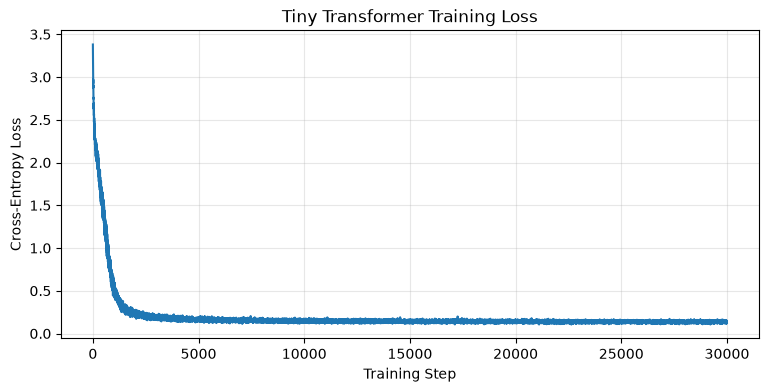

In [33]:
# ============================================================
# CELL 14F: VISUALIZE TRAINING LOSS
# ============================================================
# Purpose:
# Observe whether the model's prediction error decreases
# during training.
#
# A decreasing training loss suggests that the model is
# learning patterns in the training corpus.
#
# However, lower training loss does NOT guarantee that
# the model generalizes to unseen text.
# ============================================================

plt.figure(figsize=(9, 4))
plt.plot(loss_history)
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Tiny Transformer Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [34]:
# ============================================================
# CELL 14G: EVALUATE THE TRAINED MODEL
# ============================================================
# IMPORTANT: Repeated training sentences also appear in validation.
# This validation score does not measure genuine generalization.
# Purpose:
# Training loss measures performance on training examples.
#
# Validation loss measures performance on held-out examples.
#
# Comparing them helps us detect possible overfitting.
#
# Our synthetic corpus repeats many sentences, so the
# validation set is not truly independent in content.
#
# For meaningful generalization evaluation, use a corpus
# with genuinely distinct training and validation examples.
# ============================================================

@torch.no_grad()
def evaluate(model, source, batches=20):
    """Estimate average loss over randomly sampled batches."""
    model.eval()
    losses = []

    for _ in range(batches):
        x, y = get_batch(source)
        losses.append(calculate_loss(model(x), y).item())

    model.train()
    return sum(losses) / len(losses)

train_loss = evaluate(model, train_data)
val_loss = evaluate(model, val_data)

print("Training loss:", round(train_loss, 4))
print("Validation loss:", round(val_loss, 4))

Training loss: 0.1341
Validation loss: 0.1394


# PART 8: GENERATE TEXT

In [35]:
# ============================================================
# CELL 14H: COMPARE TEXT BEFORE AND AFTER TRAINING
# ============================================================
# Purpose:
# Compare text from random weights with text from learned weights.
# The two outputs use the same prompt and sampling settings.
# ============================================================

AFTER_TRAINING = generate_text(model, "students ", max_new_tokens=60, temperature=0.7)
print("BEFORE TRAINING:", repr(BEFORE_TRAINING))
print("AFTER TRAINING: ", repr(AFTER_TRAINING))


BEFORE TRAINING: 'students jfvglfj vxpkperyk\nlgrnsk.ghmwedixse\nxvftux\npk.emhgelvxgliggi'
AFTER TRAINING:  'students learn python programming.\nstudents develop artificial intell'


In [36]:
# output parameter
print("Embedding dimension:", EMBEDDING_DIM)
print("Attention heads:", NUM_HEADS)
print("Transformer Layers:", NUM_LAYERS)
print("Feed-Forward Dimension:", FEEDFORWARD_DIM)
print("Context Length:", CONTEXT_LENGTH)
print("BATCH_SIZE:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)

print("Total Trainable Parameters:", total_parameters)
print("Final Training Loss:", round(train_loss, 4))
print("Training Time:", round(elapsed, 2) ,"s")
print("Generated Text:", repr(AFTER_TRAINING))


Embedding dimension: 48
Attention heads: 2
Transformer Layers: 1
Feed-Forward Dimension: 192
Context Length: 32
BATCH_SIZE: 16
Learning Rate: 0.001
Total Trainable Parameters: 32523
Final Training Loss: 0.1341
Training Time: 135.69 s
Generated Text: 'students learn python programming.\nstudents develop artificial intell'


## Step 1.1: Run the Original Small Language Model

Everything above is the class notebook, run top to bottom with the **original Cell 2 values** (48 / 2 heads / 1 layer / 192). The table is built from the variables of that run, so it cannot drift from the outputs above.

**Two notes on reading it.** *Final Training Loss* is Cell 14G's `evaluate()`: the mean over 20 random training batches after training. It is steadier than the last single step's loss printed by Cell 14A, which `training_results.csv` records. *Device:* Cell 1 prints `cpu`, but Cell 5A switches `DEVICE` to the Apple GPU (`mps`) before the model is built, so training ran on MPS.

In [37]:
from IPython.display import Markdown, display

baseline = {
    'Embedding Dimension': EMBEDDING_DIM,
    'Attention Heads': NUM_HEADS,
    'Transformer Layers': NUM_LAYERS,
    'Feed-Forward Dimension': FEEDFORWARD_DIM,
    'Context Length': CONTEXT_LENGTH,
    'Batch Size': BATCH_SIZE,
    'Learning Rate': LEARNING_RATE,
    'Training Steps': TRAINING_STEPS,
    'Total Trainable Parameters': f'{total_parameters:,}',
    'Final Training Loss': round(train_loss, 4),
    'Final Validation Loss': round(val_loss, 4),
    'Training Time': f'{elapsed:.1f} s on {DEVICE}',
    'Generated Text': repr(AFTER_TRAINING),
}
display(Markdown('| Configuration | Original Value |\n|---|---|\n' + '\n'.join(
    f'| {k} | {str(v).replace("|", "/")} |' for k, v in baseline.items())))

| Configuration | Original Value |
|---|---|
| Embedding Dimension | 48 |
| Attention Heads | 2 |
| Transformer Layers | 1 |
| Feed-Forward Dimension | 192 |
| Context Length | 32 |
| Batch Size | 16 |
| Learning Rate | 0.001 |
| Training Steps | 30000 |
| Total Trainable Parameters | 32,523 |
| Final Training Loss | 0.1341 |
| Final Validation Loss | 0.1394 |
| Training Time | 135.7 s on mps |
| Generated Text | 'students learn python programming.\nstudents develop artificial intell' |

## Step 1.2: Experiment With Architecture Configurations

The five configurations from the brief. To keep the comparison fair, every experiment uses the **same training loop as Cell 14A**, the same corpus, `TRAINING_STEPS`, `LEARNING_RATE`, `BATCH_SIZE` and `CONTEXT_LENGTH`, and starts from a **newly initialized model with the same seed**. Only the four Cell 2 architecture values change.

Recorded per experiment: trainable parameters, final training loss (Cell 14G's `evaluate()`, averaged over 20 batches, plus validation loss), wall-clock training time, and text generated from the same prompt, length, temperature and random seed.

Experiment 2 is the original configuration, so it repeats Step 1.1 inside this controlled loop. Its numbers differ slightly from Step 1.1 because the class cells before Cell 14A take one extra optimizer step and draw extra random batches.

In [38]:
EXPERIMENTS = {
    1: {'embedding_dim': 24, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 96},
    2: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 192},
    3: {'embedding_dim': 48, 'num_heads': 4, 'num_layers': 1, 'feedforward_dim': 192},
    4: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 2, 'feedforward_dim': 192},
    5: {'embedding_dim': 96, 'num_heads': 4, 'num_layers': 2, 'feedforward_dim': 384},
}
GEN_PROMPT, GEN_TOKENS, GEN_TEMPERATURE = 'students ', 60, 0.7


def sync():
    if str(DEVICE) == 'mps':
        torch.mps.synchronize()


def run_experiment(number, config):
    """Fresh model, Cell 14A's training loop, then measure. Returns (model, row)."""
    random.seed(SEED)
    torch.manual_seed(SEED)
    exp_model = TinyTransformerLM(vocab_size=VOCAB_SIZE, context_length=CONTEXT_LENGTH, **config).to(DEVICE)
    params = sum(p.numel() for p in exp_model.parameters() if p.requires_grad)
    exp_optimizer = torch.optim.AdamW(exp_model.parameters(), lr=LEARNING_RATE)

    exp_model.train()
    history = []
    sync()
    start = time.perf_counter()
    for step in range(TRAINING_STEPS):
        xb, yb = get_batch(train_data)
        exp_optimizer.zero_grad()
        loss = calculate_loss(exp_model(xb), yb)
        loss.backward()
        exp_optimizer.step()
        history.append(loss.item())
    sync()
    seconds = time.perf_counter() - start

    torch.manual_seed(SEED)
    final_train = evaluate(exp_model, train_data)
    final_val = evaluate(exp_model, val_data)
    torch.manual_seed(SEED)
    text = generate_text(exp_model, GEN_PROMPT, max_new_tokens=GEN_TOKENS, temperature=GEN_TEMPERATURE)
    row = {'Experiment': number, **config, 'Total Parameters': params,
           'Final Training Loss': round(final_train, 4), 'Validation Loss': round(final_val, 4),
           'Last-Step Loss': round(history[-1], 4), 'Training Time (s)': round(seconds, 1),
           'Generated Text': text}
    print(f"Experiment {number}: {params:,} params | loss {final_train:.4f} | {seconds:.1f}s | {text!r}")
    return exp_model, history, row


experiment_models, experiment_histories, experiment_rows = {}, {}, []
for number, config in EXPERIMENTS.items():
    m, h, row = run_experiment(number, config)
    experiment_models[number], experiment_histories[number] = m, h
    experiment_rows.append(row)

experiments_df = pd.DataFrame(experiment_rows)
experiments_df.to_csv('architecture_experiments.csv', index=False)

Experiment 1: 9,363 params | loss 0.1458 | 127.2s | 'students experiment with language models.\nartificial intelligence can'


Experiment 2: 32,523 params | loss 0.1332 | 128.8s | 'students learn python programming.\nstudents develop artificial intell'


Experiment 3: 32,523 params | loss 0.1317 | 127.5s | 'students learn python programming.\nstudents develop artificial intell'


Experiment 4: 60,795 params | loss 0.1283 | 190.8s | 'students experiment with language models.\nartificial intelligence can'


Experiment 5: 232,155 params | loss 0.1239 | 200.2s | 'students experiment with language models.\nartificial intelligence can'


In [39]:
def md_table(df):
    cols = list(df.columns)
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '---|' * len(cols)]
    for _, r in df.iterrows():
        lines.append('| ' + ' | '.join(repr(v) if isinstance(v, str) and '\n' in v else str(v) for v in r) + ' |')
    return '\n'.join(lines)

config_table = experiments_df[['Experiment', 'embedding_dim', 'num_heads', 'num_layers', 'feedforward_dim']].rename(columns={
    'embedding_dim': 'Embedding Dimension', 'num_heads': 'Attention Heads',
    'num_layers': 'Transformer Layers', 'feedforward_dim': 'Feed-Forward Dimension'})
display(Markdown(md_table(config_table)))
display(Markdown(md_table(experiments_df[['Experiment', 'Total Parameters', 'Final Training Loss',
                                          'Validation Loss', 'Training Time (s)', 'Generated Text']])))

| Experiment | Embedding Dimension | Attention Heads | Transformer Layers | Feed-Forward Dimension |
|---|---|---|---|---|
| 1 | 24 | 2 | 1 | 96 |
| 2 | 48 | 2 | 1 | 192 |
| 3 | 48 | 4 | 1 | 192 |
| 4 | 48 | 2 | 2 | 192 |
| 5 | 96 | 4 | 2 | 384 |

| Experiment | Total Parameters | Final Training Loss | Validation Loss | Training Time (s) | Generated Text |
|---|---|---|---|---|---|
| 1 | 9363 | 0.1458 | 0.1463 | 127.2 | 'students experiment with language models.\nartificial intelligence can' |
| 2 | 32523 | 0.1332 | 0.1348 | 128.8 | 'students learn python programming.\nstudents develop artificial intell' |
| 3 | 32523 | 0.1317 | 0.1328 | 127.5 | 'students learn python programming.\nstudents develop artificial intell' |
| 4 | 60795 | 0.1283 | 0.1304 | 190.8 | 'students experiment with language models.\nartificial intelligence can' |
| 5 | 232155 | 0.1239 | 0.1277 | 200.2 | 'students experiment with language models.\nartificial intelligence can' |

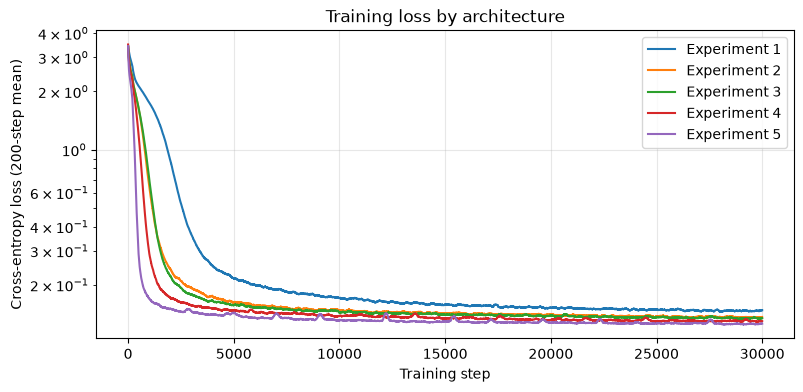

Experiment 1: smoothed loss < 0.5 from step 2564
Experiment 2: smoothed loss < 0.5 from step 1147
Experiment 3: smoothed loss < 0.5 from step 1181
Experiment 4: smoothed loss < 0.5 from step 771
Experiment 5: smoothed loss < 0.5 from step 399


In [40]:
# Loss curves, smoothed over 200 steps so the five runs can be told apart.
plt.figure(figsize=(9, 4))
for number, history in experiment_histories.items():
    plt.plot(pd.Series(history).rolling(200, min_periods=1).mean(), label=f'Experiment {number}')
plt.xlabel('Training step')
plt.ylabel('Cross-entropy loss (200-step mean)')
plt.yscale('log')
plt.title('Training loss by architecture')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# How fast each one learned: first step at which the smoothed loss fell below 0.5.
for number, history in experiment_histories.items():
    smooth = pd.Series(history).rolling(200, min_periods=1).mean()
    below = smooth[smooth < 0.5]
    print(f'Experiment {number}: smoothed loss < 0.5 from step', int(below.index[0]) if len(below) else 'never')

### Selecting the checkpoint for Parts 2-4

**Experiment 4** (48 / 2 heads / 2 layers / 192) is carried forward. Adding the second layer gave the largest improvement for its cost: final loss fell from 0.1332 to 0.1283, and the model learned faster (smoothed loss below 0.5 by step 771 instead of 1,147). Experiment 5 reaches a slightly lower loss (0.1239), but it has 3.8x the parameters and produces exactly the same generated text, so the extra size buys nothing visible. The cell below saves the model once as `slm_selected.pt`, and Parts 2, 3 and 4 all load that same file. It is git-ignored (`*.pt`), so re-running the notebook recreates it.

In [41]:
SELECTED_EXPERIMENT = 4
model = experiment_models[SELECTED_EXPERIMENT]
model.eval()
selected_config = EXPERIMENTS[SELECTED_EXPERIMENT]
torch.save({
    'model_state': model.state_dict(),
    'vocab': chars,
    'experiment': SELECTED_EXPERIMENT,
    'config': {**selected_config, 'context_length': CONTEXT_LENGTH},
    'training': {'steps': TRAINING_STEPS, 'learning_rate': LEARNING_RATE,
                 'batch_size': BATCH_SIZE, 'seed': SEED},
}, 'slm_selected.pt')
print('Saved slm_selected.pt:', selected_config, '| params', f"{sum(p.numel() for p in model.parameters()):,}")

Saved slm_selected.pt: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 2, 'feedforward_dim': 192} | params 60,795


# Testing Variety in Text Generation using Temperature

In [42]:
# ============================================================
# CELL 15A: TEMPERATURE WITH FIVE POSSIBLE NEXT WORDS
# ============================================================
# Purpose:
# Demonstrate temperature using simple, fixed logits.
#
# Imagine the prompt:
# "Students love ..."
#
# The model assigns the following hypothetical scores.
#
# We change ONLY temperature.
# ============================================================

words = ["Python", "Django", "Coffee", "Exams", "Homework"]
logits_demo = torch.tensor([5.0, 4.0, 3.0, 2.0, 1.0])

temperatures = [0.2, 0.5, 1.0, 2.0] #[0.1, 0.5, 1.0, 2.0, 5.0]

print(f"{'Temperature':<14}", end="")

for word in words:
    print(f"{word:<12}", end="")

print()

for temperature in temperatures:

    probs = F.softmax(logits_demo / temperature, dim=0)

    print(f"{temperature:<14.1f}", end="")

    for probability in probs:
        print(f"{probability.item():<12.3f}", end="")

    print()

Temperature   Python      Django      Coffee      Exams       Homework    
0.2           0.993       0.007       0.000       0.000       0.000       
0.5           0.865       0.117       0.016       0.002       0.000       
1.0           0.636       0.234       0.086       0.032       0.012       
2.0           0.429       0.260       0.158       0.096       0.058       


In [43]:
# ============================================================
# CELL 15B: HOW TEMPERATURE CHANGES TOKEN PROBABILITIES
# ============================================================
# Purpose:
# Show how temperature changes the probability distribution
# over possible next tokens.
#
# Lower temperature:
#   Concentrates probability on the highest-scoring tokens.
#
# Higher temperature:
#   Distributes probability across more possible tokens.
#
# IMPORTANT:
# We use the SAME model, SAME prompt, and SAME logits.
# Only the temperature changes.
# ============================================================

prompt = "students "

model.eval()

with torch.no_grad():
    input_ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    temperature_logits = model(input_ids)[:, -1, :].squeeze()

temperatures = [0.2, 0.5, 1.0, 2.0] #[0.01, 0.1, 0.5, 1.0, 2.0, 5.0]

print(f"{'Temperature':<15} {'Top Character':<18} {'Probability':<15} {'Entropy (bits)':<15}")
print("-" * 70)

for temperature in temperatures:
    probs = F.softmax(temperature_logits / temperature, dim=-1)

    top_id = torch.argmax(probs).item()
    top_prob = probs[top_id].item()
    entropy = -(probs * probs.clamp_min(1e-12).log2()).sum().item()

    print(f"{temperature:<15.2f} {repr(itos[top_id]):<18} {top_prob:<15.4f} {entropy:<15.4f}")

Temperature     Top Character      Probability     Entropy (bits) 
----------------------------------------------------------------------
0.20            'e'                0.9037          0.5588         
0.50            'e'                0.5422          1.9499         
1.00            'e'                0.3316          2.5457         
2.00            'e'                0.2058          3.3821         


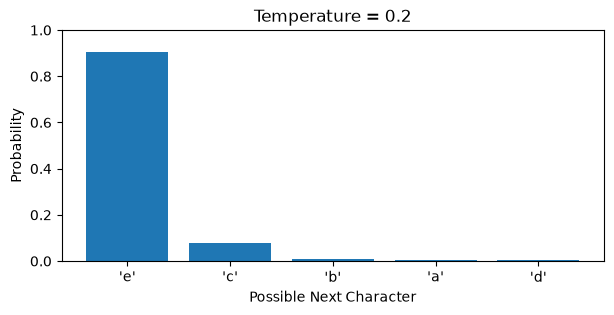

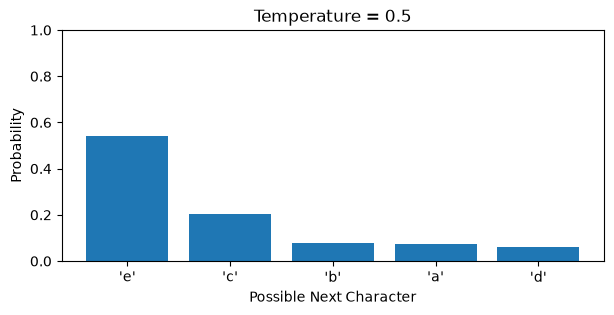

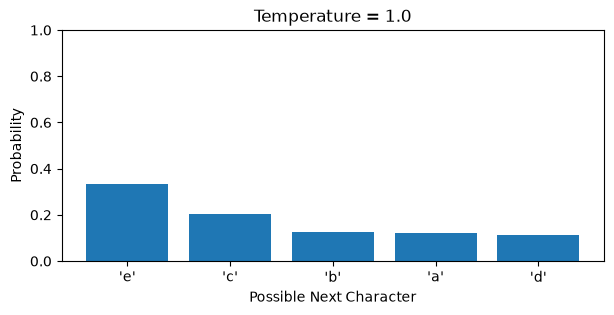

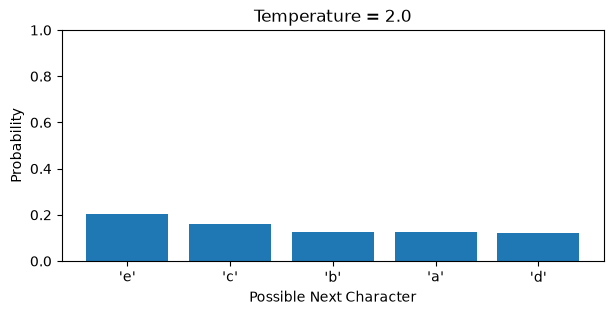

In [44]:
# ============================================================
# CELL 15C: VISUALIZE TEMPERATURE AND TOKEN PROBABILITIES
# ============================================================
# Purpose:
# Visualize how temperature redistributes probability
# across possible next characters.
#
# We select the five highest-scoring tokens at temperature 1.
# Then compare their probabilities at different temperatures.
#
# The model and logits remain unchanged.
# ============================================================



temperatures = [0.2, 0.5, 1.0, 2.0] #[0.1, 0.5, 1.0, 2.0, 5.0]
top_ids = torch.topk(temperature_logits, k=5).indices

for temperature in temperatures:

    probs = F.softmax(temperature_logits / temperature, dim=-1)
    selected_probs = probs[top_ids].detach().cpu().numpy()
    labels = [repr(itos[i.item()]) for i in top_ids]

    plt.figure(figsize=(7, 3))
    plt.bar(labels, selected_probs)
    plt.title(f"Temperature = {temperature}")
    plt.xlabel("Possible Next Character")
    plt.ylabel("Probability")
    plt.ylim(0, 1)
    plt.show()

In [45]:
# ============================================================
# CELL 15D: OBSERVE GENERATION VARIETY
# ============================================================
# Purpose:
# Generate multiple responses at each temperature.
#
# Low temperature:
#   Repeated generations tend to be similar.
#
# High temperature:
#   Repeated generations tend to be more diverse.
#
# We keep the model, prompt, and output length constant.
# ============================================================

prompt = "students "

temperatures = [0.2, 0.5, 1.0, 2.0] #[0.01, 0.1, 0.5, 1.0, 2.0]

for temperature in temperatures:

    print("\n" + "=" * 65)
    print(f"TEMPERATURE: {temperature}")
    print("=" * 65)

    for run in range(3):
        response = generate_text(
            model,
            prompt,
            max_new_tokens=60,
            temperature=temperature)

        print(f"Run {run + 1}: {response!r}")


TEMPERATURE: 0.2


Run 1: 'students experiment with language models.\nartificial intelligence can'


Run 2: 'students build django applications.\nstudents learn python programming'
Run 3: 'students experiment with language models.\nartificial intelligence can'

TEMPERATURE: 0.5


Run 1: 'students experiment with language models.\nartificial intelligence can'


Run 2: 'students experiment with language models.\nartificial intelligence can'


Run 3: 'students create innovative startup applications.\ndjango applications '

TEMPERATURE: 1.0
Run 1: 'students experiment with language models.\nartificial intelligence can'


Run 2: 'students learn pystems.\nlanguage models predict informatics.\nstudents'
Run 3: 'students are building useful software products.\nsmall language models'

TEMPERATURE: 2.0


Run 1: 'students create innovative startup applications.\ndjango applications '


Run 2: 'students develop artificial intelligence systems.\nlanguage models pre'
Run 3: 'students are building useful software products.\nsmall language models'


## Step 1.3: Test Generation Temperatures

The class cells above show how temperature reshapes the next-character distribution of the **selected model**. Below, the selected model's weights stay fixed. It generates from the same prompt with the same maximum length at each temperature, three runs each with fixed seeds, so the table can be reproduced exactly.

Two measures support the observations. **Real-word rate** is the share of generated words that are words from the training corpus. **Distinct runs** counts how many of the three runs differ from each other.

In [46]:
corpus_words = set(text.replace('.', ' ').split())
TEMPERATURES = [0.2, 0.5, 1.0, 2.0]
temperature_rows = []
for temperature in TEMPERATURES:
    runs = []
    for run in range(3):
        torch.manual_seed(SEED + run)
        runs.append(generate_text(model, GEN_PROMPT, max_new_tokens=GEN_TOKENS, temperature=temperature))
    words = [w for r in runs for w in r.replace('.', ' ').split()]
    real = sum(w in corpus_words for w in words) / len(words)
    for run, out in enumerate(runs, start=1):
        temperature_rows.append({'Temperature': temperature, 'Run': run, 'Generated Text': out,
                                 'Real-word rate (3 runs)': f'{real:.0%}',
                                 'Distinct runs': len(set(runs))})
temperature_df = pd.DataFrame(temperature_rows)
display(Markdown(md_table(temperature_df)))

| Temperature | Run | Generated Text | Real-word rate (3 runs) | Distinct runs |
|---|---|---|---|---|
| 0.2 | 1 | 'students experiment with language models.\nartificial intelligence can' | 100% | 1 |
| 0.2 | 2 | 'students experiment with language models.\nartificial intelligence can' | 100% | 1 |
| 0.2 | 3 | 'students experiment with language models.\nartificial intelligence can' | 100% | 1 |
| 0.5 | 1 | 'students experiment with language models.\nartificial intelligence can' | 96% | 2 |
| 0.5 | 2 | 'students experiment with language models.\nartificial intelligence can' | 96% | 2 |
| 0.5 | 3 | 'students develop artificial intelligence systems.\nlanguage models pre' | 96% | 2 |
| 1.0 | 1 | 'students experiment with language models.\nartificial intelligence can' | 96% | 3 |
| 1.0 | 2 | 'students create innovative startup applications.\ndjango applications ' | 96% | 3 |
| 1.0 | 3 | 'students develop artificial intelligence systems.\nlanguage models pre' | 96% | 3 |
| 2.0 | 1 | 'students experiment with language models.\nstudents contextuefual info' | 67% | 3 |
| 2.0 | 2 | 'students previocts characters usiatics.\ndjokan runsget attention mech' | 67% | 3 |
| 2.0 | 3 | 'students develop artificial intelligence systems.\nlanguage models pre' | 67% | 3 |

### Step 1.3 results table with observations

| Temperature | Run | Generated Text | Observations |
|---|---|---|---|
| 0.2 | 1 | 'students experiment with language models.\nartificial intelligence can' | All three runs identical, 100% real words. The top character holds ~90% of the probability, so sampling almost always takes it. Safe but repetitive. |
| 0.2 | 2 | 'students experiment with language models.\nartificial intelligence can' | ″ |
| 0.2 | 3 | 'students experiment with language models.\nartificial intelligence can' | ″ |
| 0.5 | 1 | 'students experiment with language models.\nartificial intelligence can' | Some variety (2 distinct runs), still 96% real words. Every run is a correct corpus sentence. |
| 0.5 | 2 | 'students experiment with language models.\nartificial intelligence can' | ″ |
| 0.5 | 3 | 'students develop artificial intelligence systems.\nlanguage models pre' | ″ |
| 1.0 | 1 | 'students experiment with language models.\nartificial intelligence can' | All three runs differ and every one is still a correct sentence (96% real words). The model's own uncertainty shows, without errors. |
| 1.0 | 2 | 'students create innovative startup applications.\ndjango applications ' | ″ |
| 1.0 | 3 | 'students develop artificial intelligence systems.\nlanguage models pre' | ″ |
| 2.0 | 1 | 'students experiment with language models.\nstudents contextuefual info' | All runs differ and the real-word rate drops to 67%. Invented words such as *contextuefual*, *previocts* and *djokan* appear as unlikely characters get sampled. |
| 2.0 | 2 | 'students previocts characters usiatics.\ndjokan runsget attention mech' | ″ |
| 2.0 | 3 | 'students develop artificial intelligence systems.\nlanguage models pre' | ″ |

## Step 1.4: Analysis

Every number here is from the tables in Steps 1.1-1.3 of this run.

1. **Which architecture contained the most trainable parameters?**
Experiment 5 (96-dim embeddings, 4 heads, 2 layers, 384 FF) with **232,155** parameters, 7.1x the original 32,523. Doubling the embedding width scales the attention projections and feed-forward layers quadratically, which is why it grows far faster than adding a layer (Experiment 4: 60,795).

2. **Did increasing the number of attention heads increase the total parameter count?**
**No.** Experiments 2 and 3 both have exactly **32,523** parameters. More heads only split the same 48-dimensional projections into 4 heads of 12 dimensions instead of 2 of 24. The Q/K/V and output matrices stay 48x48. Loss barely moved (0.1332 → 0.1317).

3. **Did increasing the number of Transformer layers improve generated text?**
It improved learning, but not the visible text. The second layer (Experiment 4 vs 2) lowered final loss from 0.1332 to 0.1283 and reached a smoothed loss below 0.5 at step 771 instead of 1,147. Both models still output correct sentences copied from the corpus. A corpus of 20 sentences repeated 100 times is memorised by every configuration, so better language modelling has nothing left to show in the text.

4. **Which architecture required the most training time?**
Experiment 5, at **200.2 s**. It took only 5% longer than Experiment 4 (190.8 s) despite having 3.8x the parameters. On the Apple GPU (MPS) these models are too small to keep it busy, so time follows the number of sequential layers rather than parameters. One-layer models took 127-129 s and two-layer models 191-200 s.

5. **Did the model with the most parameters necessarily generate the best text?**
**No.** Experiment 5 had the lowest loss (0.1239), but its sample is identical to Experiment 4's and Experiment 1's. Experiment 1 has only 9,363 parameters, 25x fewer. With this tiny corpus, every size reaches the memorisation ceiling. Extra parameters cost memory and compute without producing better text. That is why Experiment 4 was carried forward rather than 5.

6. **How did changing temperature affect the generated responses?**
Low temperature gives deterministic, conservative text, and high temperature trades correctness for variety. At **0.2** all three runs were identical, and 100% of the words were real corpus words; the top character's probability was 0.90 (entropy 0.56 bits). At **0.5** there were 2 distinct runs and 96% real words, and at **1.0** 3 distinct runs, still 96% real words. At **2.0** the real-word rate fell to **67%**, with invented words such as *contextuefual*, *previocts* and *djokan*. The distribution flattened to 3.38 bits, so unlikely characters got sampled.

# Part 2: Retrieval-Augmented Generation Using Our SLM

**Question:** can retrieved documents change what our Small Language Model says, without changing a single weight?

**Pipeline (Week 6 RAG notebook, adapted):** load the selected SLM checkpoint → build a new knowledge base → ask without retrieval (baseline) → TF-IDF + cosine-similarity retrieval → put the retrieved text into the SLM's input → generate → score → analyse.

**Model:** the checkpoint selected in Part 1 (`slm_selected.pt`, Experiment 4: 48-dim embeddings, 2 heads, 2 layers, 192 FF, 32-character context). Part 3 (fine-tuning) starts from the same file. The model is never trained in this notebook, and the last cell proves its weights are unchanged.

**Compatibility adjustments to the class RAG pipeline (all allowed by the brief):**
1. **Tokenizer.** The SLM is character-level and only knows the 27 characters of its corpus: lowercase letters except `q` and `z`, space, `.` and newline. The knowledge base is written in that alphabet, and the notebook asserts it.
2. **Context window.** The class prompt (instructions + documents + question) is hundreds of characters long, but this model reads only the last **32**. The prompt is therefore just `evidence + "\n" + question + "\n"`. Evidence is cut to whatever space the question leaves. Each row records whether the answer fact survived that cut.
3. **No instructions.** The SLM was never trained to follow instructions, so a system prompt would only use up context.
4. **Greedy decoding.** The answer is always the most likely next character (`temperature=None`), so every condition is deterministic and directly comparable. Part 3 uses the identical setting.

In [47]:
import json
import sys
import time
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, str(Path.cwd().parent))  # ../slm_common.py
from slm_common import SLM, score_answer

slm = SLM(Path("slm_selected.pt"))   # saved by Part 1 above
rag_model = slm.new_model()
weights_at_start = {k: v.clone() for k, v in rag_model.state_dict().items()}

print("Checkpoint:", slm.path.name, "| experiment", slm.experiment, "|", slm.config)
print("Parameters:", f"{sum(p.numel() for p in rag_model.parameters()):,}")
print("Vocabulary:", repr("".join(slm.vocab)))

Checkpoint: slm_selected.pt | experiment 4 | {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 2, 'feedforward_dim': 192, 'context_length': 32}
Parameters: 60,795
Vocabulary: '\n .abcdefghijklmnoprstuvwxy'


## Step 2.1: Create a New Knowledge Base

Seven short documents about **Lumen Prep**, a fictional interview-preparation startup invented for this assignment. They cover pricing, trial, refunds, support hours, a product feature, a discount and cancellation. Each has a unique ID. The file is `../knowledge_base.json`, shared with Part 3 (fine-tuning) so both use exactly the same facts.

Checked below: no document uses a character outside the SLM's vocabulary, and no document sentence appears in the SLM's training corpus.

In [48]:
kb = json.loads((Path("../knowledge_base.json")).read_text())
documents, questions = kb["documents"], kb["questions"]

corpus = Path("training_corpus.txt").read_text()
for d in documents:
    assert not slm.unsupported(d["text"]), (d["id"], slm.unsupported(d["text"]))
    assert d["text"] not in corpus, d["id"]
assert len({d["id"] for d in documents}) == len(documents)

print(kb["company"])
display(pd.DataFrame(documents))

Lumen Prep, a fictional interview-preparation startup invented for this assignment. None of these facts appear in the SLM training corpus.


,id,title,text
0,LP-01,Pricing,the lumen pro plan costs nine dollars a month.
1,LP-02,Free trial,new users get a seven day free trial.
2,LP-03,Refund policy,refunds are paid back within five days.
3,LP-04,Support hours,support is open from nine to five on weekdays.
4,LP-05,Mock interviews,pro members get two mock interviews each week.
5,LP-06,Student discount,students with a school email get half off.
6,LP-07,Cancellation,you can cancel the pro plan at any time.


## Step 2.2: Test the SLM Without RAG

Five questions about the knowledge base. Each one names its source document and the key fact a correct answer must contain. The baseline prompt is just the question and a newline, the same format Part 3 uses, so Part 3's "before" answers must match these exactly.

**Response quality (1-10)** is computed by `score_answer` in `slm_common.py`, so it can be audited and is identical in Parts 2, 3 and 4:
- **Accuracy (0-6):** all key facts present scores 6, some 3, none 0.
- **Relevance (0-2):** the share of the source document's words that appear in the answer.
- **Clarity (0-2):** the share of the answer's words that are real words from the corpus or the knowledge base.

In [49]:
known_words = set(corpus.replace(".", " ").split()) | {
    w.strip(".") for d in documents for w in d["text"].split()}
doc_by_id = {d["id"]: d for d in documents}
STOP = {"the", "a", "an", "is", "are", "of", "to", "on", "at", "from", "with", "can", "get", "each"}

def topic_words(source_id):
    return [w.strip(".") for w in doc_by_id[source_id]["text"].split() if w.strip(".") not in STOP]

def ask(question, active_model=rag_model):
    return slm.generate(active_model, question + "\n", max_new_tokens=50)

baseline_rows = []
for q in questions:
    answer = ask(q["question"])
    s = score_answer(answer, q["key_facts"], topic_words(q["source"]), known_words)
    baseline_rows.append({"Question": q["id"], "Text": q["question"], "SLM Response Without RAG": answer,
                          "Correct": s["correct"], "Quality (1-10)": s["score"]})
baseline_df = pd.DataFrame(baseline_rows)
baseline_df

,Question,Text,SLM Response Without RAG,Correct,Quality (1-10)
0,Q1,what does lumen pro cost,small language models can run on local computers.,False,2
1,Q2,how long is the free trial,inference uses previously learned parameters.,False,2
2,Q3,when are refunds paid back,the university offers courses in informatics.,False,2
3,Q4,when is support open,traches artificial intelligence systems.,False,2
4,Q5,how many mock interviews,tartup applications use models and views.,False,2


## Step 2.3: Apply RAG to the Same SLM

The retriever is the class notebook's **TF-IDF + cosine similarity** index. Following the Week 6 RAG notebook, retrieval is checked on its own first (recall@k), because a wrong answer can come from the retriever or the generator and the two must not be confused.

In [50]:
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
doc_matrix = vectorizer.fit_transform([d["title"].lower() + " " + d["text"] for d in documents])
print("TF-IDF matrix:", doc_matrix.shape)

def retrieve(query, top_k=1):
    scores = cosine_similarity(vectorizer.transform([query]), doc_matrix)[0]
    order = scores.argsort()[::-1][:top_k]
    return [{**documents[i], "score": round(float(scores[i]), 3)} for i in order]

recall = []
for q in questions:
    row = {"Question": q["id"], "Expected": q["source"]}
    for k in (1, 2, 3, 5):
        row[f"recall@{k}"] = q["source"] in [d["id"] for d in retrieve(q["question"], k)]
    row["Top-1 (score)"] = "{id} ({score})".format(**retrieve(q["question"], 1)[0])
    recall.append(row)
display(pd.DataFrame(recall))

TF-IDF matrix: (7, 68)


,Question,Expected,recall@1,recall@2,recall@3,recall@5,Top-1 (score)
0,Q1,LP-01,True,True,True,True,LP-01 (0.459)
1,Q2,LP-02,True,True,True,True,LP-02 (0.756)
2,Q3,LP-03,True,True,True,True,LP-03 (0.577)
3,Q4,LP-04,True,True,True,True,LP-04 (0.696)
4,Q5,LP-05,True,True,True,True,LP-05 (0.805)


### Building the prompt inside a 32-character window

`build_rag_prompt` puts the retrieved text first and the question last, as in the class notebook, so the model always sees the whole question. The evidence gets whatever space is left: `32 - len(question) - 2` characters. Higher-ranked documents come first, so extra documents can only add text after the best one. They never push it out. `fact_in_window` records whether the key fact was still inside the 32 characters the model reads.

In [51]:
CONTEXT = rag_model.context_length

def build_rag_prompt(question, docs):
    tail = question + "\n"
    budget = max(0, CONTEXT - len(tail) - 1)
    evidence = " ".join(d["text"] for d in docs)[:budget]
    return (evidence + "\n" + tail)[-CONTEXT:]

example = questions[0]
prompt = build_rag_prompt(example["question"], retrieve(example["question"], 1))
print(f"{len(prompt)} characters the model actually reads: {prompt!r}")
print("Full retrieved document:", repr(retrieve(example["question"], 1)[0]["text"]))

32 characters the model actually reads: 'the lu\nwhat does lumen pro cost\n'
Full retrieved document: 'the lumen pro plan costs nine dollars a month.'


In [52]:
TOP_K = [1, 2, 3, 5]
rag_rows = []
for q in questions:
    for k in TOP_K:
        docs = retrieve(q["question"], k)
        prompt = build_rag_prompt(q["question"], docs)
        start = time.perf_counter()
        answer = slm.generate(rag_model, prompt, max_new_tokens=50)
        seconds = time.perf_counter() - start
        s = score_answer(answer, q["key_facts"], topic_words(q["source"]), known_words)
        rag_rows.append({
            "Question": q["id"], "Top-K": k,
            "Retrieved Documents": ", ".join(d["id"] for d in docs),
            "Model input": prompt,
            "Fact in window": any(f in prompt for f in q["key_facts"]),
            "Generated Response": answer,
            "Response Quality (1-10)": s["score"], "Correct": s["correct"],
            "Seconds": round(seconds, 3),
        })
rag_df = pd.DataFrame(rag_rows)
pd.set_option("display.max_colwidth", 60)
rag_df[["Question", "Top-K", "Retrieved Documents", "Generated Response", "Response Quality (1-10)"]]

,Question,Top-K,Retrieved Documents,Generated Response,Response Quality (1-10)
0,Q1,1,LP-01,small language models can run on local computers.,2
1,Q1,2,"LP-01, LP-07",small language models can run on local computers.,2
2,Q1,3,"LP-01, LP-07, LP-05",small language models can run on local computers.,2
3,Q1,5,"LP-01, LP-07, LP-05, LP-06, LP-04",small language models can run on local computers.,2
4,Q2,1,LP-02,ming,1
5,Q2,2,"LP-02, LP-07",ming,1
6,Q2,3,"LP-02, LP-07, LP-06",ming,1
7,Q2,5,"LP-02, LP-07, LP-06, LP-05, LP-04",ming,1
8,Q3,1,LP-03,the professor teaches artificial intelligence.,2
9,Q3,2,"LP-03, LP-07",the professor teaches artificial intelligence.,2


In [53]:
summary = rag_df.groupby("Top-K").agg(
    mean_quality=("Response Quality (1-10)", "mean"),
    correct=("Correct", "sum"),
    fact_in_window=("Fact in window", "sum"),
).round(2)
summary.loc["No RAG"] = [baseline_df["Quality (1-10)"].mean().round(2), baseline_df["Correct"].sum(), 0]
summary

# Did the evidence change the output at all, compared with the baseline?
changed = (rag_df.merge(baseline_df[["Question", "SLM Response Without RAG"]], on="Question")
           .assign(changed=lambda d: d["Generated Response"] != d["SLM Response Without RAG"]))
print("Responses that differ from the no-RAG baseline:", int(changed["changed"].sum()), "of", len(changed))
display(summary)

Responses that differ from the no-RAG baseline: 12 of 20


,mean_quality,correct,fact_in_window
Top-K,,,
1,1.6,0.0,0.0
2,1.6,0.0,0.0
3,1.6,0.0,0.0
5,1.6,0.0,0.0
No RAG,2.0,0.0,0.0


In [54]:
# What the model reads, and what it does with it, for every question at top-1.
for _, r in rag_df[rag_df["Top-K"] == 1].iterrows():
    print(f"{r['Question']}  input: {r['Model input']!r}")
    print(f"     output: {r['Generated Response']!r}   fact in window: {r['Fact in window']}\n")

Q1  input: 'the lu\nwhat does lumen pro cost\n'
     output: 'small language models can run on local computers.'   fact in window: False

Q2  input: 'new \nhow long is the free trial\n'
     output: 'ming'   fact in window: False

Q3  input: 'refu\nwhen are refunds paid back\n'
     output: 'the professor teaches artificial intelligence.'   fact in window: False

Q4  input: 'support is\nwhen is support open\n'
     output: 'trage uage models predict the next token.'   fact in window: False

Q5  input: 'pro me\nhow many mock interviews\n'
     output: 'tartup applications use models and views.'   fact in window: False



### Configuration B: making room for the evidence

Configuration A, the class layout above, keeps the whole question, so the key fact lands inside the window in **0 of 20** prompts. That only shows the window is too small, not whether the SLM can use evidence. Configuration B applies the compatibility adjustment the brief allows: it gives the evidence the space the question doesn't need.
- **Compact question:** question words are dropped. `what does lumen pro cost` becomes `lumen pro cost`.
- **Keyword snippet:** from each retrieved document, it keeps the characters next to the query's keywords instead of the document's first characters.
- **Shared budget:** with top-k > 1, the evidence space is split evenly across the k documents, so this is where extra documents now compete for space.

The snippet rule uses only the query and the documents. It never sees the answer, so it is a fair retriever-side adjustment.

In [55]:
import re
QUESTION_STOP = {"what", "does", "how", "long", "is", "the", "when", "are", "many", "do", "a"}

def compact_question(question):
    """Drop question words: the model needs the topic, not the grammar."""
    return " ".join(w for w in question.split() if w not in QUESTION_STOP)

def keyword_snippet(text, keywords, size):
    """`size` characters of a document next to the query's keywords: the text after
    the last keyword if enough follows it, otherwise the text just before the first."""
    t = text.rstrip(".")
    hits = [(m.start(), m.end()) for k in keywords for m in re.finditer(re.escape(k[:4]), t)]
    if not hits:
        return t[:size]
    first = min(s for s, _ in hits)
    end = max(e for _, e in hits)
    while end < len(t) and t[end] != " ":
        end += 1
    after = t[end:].strip()
    if len(after) >= size // 2:
        return after[:size]
    return t[:first].strip()[-size:]

def build_compact_prompt(question, docs, context=CONTEXT):
    tail = compact_question(question) + "\n"
    budget = max(0, context - len(tail) - 1)
    keywords = tail.split()
    share = max(1, (budget - (len(docs) - 1)) // len(docs))
    evidence = " ".join(keyword_snippet(d["text"], keywords, share) for d in docs)[:budget]
    return (evidence + "\n" + tail)[-context:]


rag_b_rows = []
for q in questions:
    for k in TOP_K:
        docs = retrieve(q["question"], k)
        prompt = build_compact_prompt(q["question"], docs)
        answer = slm.generate(rag_model, prompt, max_new_tokens=50)
        s = score_answer(answer, q["key_facts"], topic_words(q["source"]), known_words)
        rag_b_rows.append({"Question": q["id"], "Top-K": k,
                           "Retrieved Documents": ", ".join(d["id"] for d in docs),
                           "Model input": prompt, "Fact in window": any(f in prompt for f in q["key_facts"]),
                           "Generated Response": answer,
                           "Response Quality (1-10)": s["score"], "Correct": s["correct"]})
rag_b_df = pd.DataFrame(rag_b_rows)
rag_b_df.to_csv("rag_results_config_b.csv", index=False)
for _, r in rag_b_df.iterrows():
    print(f"{r['Question']} top-{r['Top-K']}: {r['Model input']!r:42} -> {r['Generated Response']!r}  "
          f"[fact in window: {r['Fact in window']}, quality {r['Response Quality (1-10)']}]")

Q1 top-1: 'nine dollars a m\nlumen pro cost\n'       -> 'small language models can run on local computers.'  [fact in window: True, quality 2]
Q1 top-2: 'nine do plan at\nlumen pro cost\n'        -> 'small language models can run on local computers.'  [fact in window: False, quality 2]
Q1 top-3: 'nine plan memb\nlumen pro cost\n'         -> 'small language models can run on local computers.'  [fact in window: False, quality 2]
Q1 top-5: 'ni pl me st su\nlumen pro cost\n'         -> 'small language models can run on local computers.'  [fact in window: False, quality 2]
Q2 top-1: 'sers get a seven day\nfree trial\n'       -> 'ming'  [fact in window: True, quality 1]
Q2 top-2: 'seven day you can c\nfree trial\n'        -> 'inference uses previously learned parameters.'  [fact in window: True, quality 2]
Q2 top-3: 'en day you ca studen\nfree trial\n'       -> 'ming'  [fact in window: False, quality 1]
Q2 top-5: 'day you stu pro sup\nfree trial\n'        -> 'inference uses previously learne

In [56]:
# Both configurations side by side: what reached the model, and what came back.
both = pd.concat([rag_df.assign(Configuration="A: class layout"), rag_b_df.assign(Configuration="B: compact + keyword snippet")])
both.groupby(["Configuration", "Top-K"]).agg(
    fact_in_window=("Fact in window", "sum"),
    correct=("Correct", "sum"),
    mean_quality=("Response Quality (1-10)", "mean"),
    distinct_answers=("Generated Response", "nunique"),
).round(2)

fact_in_window  correct  mean_quality  \
Configuration                Top-K                                          
A: class layout              1                   0        0           1.6   
                             2                   0        0           1.6   
                             3                   0        0           1.6   
                             5                   0        0           1.6   
B: compact + keyword snippet 1                   3        0           1.8   
                             2                   1        0           1.8   
                             3                   0        0           1.6   
                             5                   0        0           1.8   

                                    distinct_answers  
Configuration                Top-K                    
A: class layout              1                     5  
                             2                     5  
                             3                     5  
                             5                     5  
B: compact + keyword snippet 1                     5  
                             2                     5  
                             3                     5  
                             5                     5

In [57]:
# RAG must not update weights: compare every tensor with the copy taken at load time.
unchanged = all(torch.equal(weights_at_start[k], v) for k, v in rag_model.state_dict().items())
print("All weights identical to the checkpoint after every RAG run:", unchanged)
assert unchanged

rag_df.to_csv("rag_results.csv", index=False)
baseline_df.to_csv("baseline_no_rag.csv", index=False)

All weights identical to the checkpoint after every RAG run: True


## Step 2.4: Analysis

Two layouts were tested on the same retriever and the same five questions. **A** is the class layout (evidence, then the full question). **B** uses a compact question plus keyword snippets, which gives the evidence the room the question doesn't need.

| Layout, top-k | Fact inside the 32-char window | Correct answers | Mean quality |
|---|---|---|---|
| A, top-1 / 2 / 3 / 5 | 0 / 0 / 0 / 0 of 5 | 0 | 1.6 |
| B, top-1 | **3 of 5** | 0 | 1.8 |
| B, top-2 | 1 of 5 | 0 | 1.8 |
| B, top-3 / 5 | 0 of 5 | 0 | 1.6 / 1.8 |
| No RAG | (no evidence) | 0 | 2.0 |

1. **Did providing retrieved information change the SLM's responses?**
Yes, in about half the cases (A: 12 of 20 differ from the baseline, B: 10 of 20), but never toward the retrieved facts. Every changed answer is another sentence from the training corpus or a fragment such as `ming`. In B the fact was literally in the input three times, for example `'nine dollars a m\nlumen pro cost\n'`. The model still answered *"small language models can run on local computers."*

2. **Did RAG improve factual accuracy?**
**No: 0 of 40 RAG answers were correct** across both layouts and all top-k values. Retrieval was not the problem: recall@1 was 5/5, and B delivered the fact into the window three times. The generator never copied it.

3. **Did retrieving more documents always improve the responses?**
**No. It made the input worse.** In A, extra documents fall outside the window, so top-1, 2, 3 and 5 give identical outputs. In B, the documents share the space, so each one gets less. Facts in the window fell from 3 (top-1) to 1 (top-2) to 0 (top-3 and top-5). The snippets shrink to `'ni pl me st su'` at top-5.

4. **How did the SLM's context-length limitation affect the results?**
It is the binding constraint on *input*. The full question takes 20-26 of the 32 characters, which leaves 4-10 for evidence, never enough for a fact (layout A). Even after compressing the question, a fact fits only when one short document gets all the remaining space (B, top-1). Q3 and Q5 still missed it. Q3's snippet `'within five d'` was cut short, and Q5's took the text after the keywords (`'each week'`) instead of the number before them.

5. **Why might RAG behave differently with a small character-level model compared with a larger pretrained language model?**
B shows it is not only the window. When the evidence *was* present, the SLM ignored it. RAG assumes the model can read a passage and answer from it, and that skill comes from pretraining on large, varied text. This model has 60,795 parameters and has seen only 20 sentences. It learned to continue those sentences, not to copy from its input. A pretrained LLM has thousands of tokens of context and has learned in-context reading, so it would answer from the same retrieved document. RAG improves a model that can already read. It cannot add that ability.

# Part 3: Fine-Tuning Our Small Language Model

**Question:** if the same SLM keeps training on a handful of new examples, does it learn the new facts? And how does that compare with handing it the facts through RAG?

**Starting point:** the checkpoint selected in Part 1 (`slm_selected.pt`, Experiment 4). Part 2 used the same file. It is not a newly initialized model. Fine-tuning works on a copy, so the untouched original stays in memory for the before/after and three-way comparisons.

**Procedure (Week 6 fine-tuning notebook, adapted to the Week 7 SLM):**
- **Data.** Question/answer pairs built from the RAG knowledge base (`../knowledge_base.json`), written in the SLM's 27-character alphabet.
- **Loss masking.** The class notebook sets question tokens to `-100` so only the answer is learned. Here every training example is *(the 32 characters before an answer character → that character)*. Question characters are context and never targets, which is the same loss masking. The 32-character window matches what the model sees at inference.
- **Optimizer and checks.** AdamW, gradient clipping, a loss curve, and proof that the weights changed (class cells 9-12).
- **Decoding.** Greedy, with the same prompt format as the Part 2 baseline (`question + "\n"`), so "before fine-tuning" must equal the no-RAG baseline exactly.

In [58]:
import copy
import json
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, str(Path.cwd().parent))  # ../slm_common.py
from slm_common import SLM, score_answer

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

slm = SLM(Path("slm_selected.pt"))   # the same checkpoint Part 2 used
base_model = slm.new_model()          # Condition A, never trained here
print("Checkpoint:", slm.path.name, "| experiment", slm.experiment, "|", slm.config)
print("Parameters:", f"{sum(p.numel() for p in base_model.parameters()):,}")

kb = json.loads((Path("../knowledge_base.json")).read_text())
documents, questions = kb["documents"], kb["questions"]
doc_by_id = {d["id"]: d for d in documents}
corpus = Path("training_corpus.txt").read_text()
known_words = set(corpus.replace(".", " ").split()) | {w.strip(".") for d in documents for w in d["text"].split()}
STOP = {"the", "a", "an", "is", "are", "of", "to", "on", "at", "from", "with", "can", "get", "each"}
topic_words = lambda sid: [w.strip(".") for w in doc_by_id[sid]["text"].split() if w.strip(".") not in STOP]

def ask(active_model, question, **kw):
    return slm.generate(active_model, question + "\n", max_new_tokens=50, **kw)

Checkpoint: slm_selected.pt | experiment 4 | {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 2, 'feedforward_dim': 192, 'context_length': 32}
Parameters: 60,795


## Step 3.1: Create Your Own Fine-Tuning Examples

Fourteen question/answer pairs: two phrasings for each of the seven knowledge-base documents. Each answer is the document's own sentence, so the fine-tuned model is taught exactly the facts RAG retrieves. The five evaluation questions are among the training phrasings, as in the class notebook.

Two **held-out** questions are written differently and are never trained on. They test whether the model learned the fact or only memorised one wording.

In [59]:
PHRASINGS = {
    "LP-01": ["what does lumen pro cost", "how much is lumen pro"],
    "LP-02": ["how long is the free trial", "is there a free trial"],
    "LP-03": ["when are refunds paid back", "how fast are refunds"],
    "LP-04": ["when is support open", "what are support hours"],
    "LP-05": ["how many mock interviews", "do pro members get mock interviews"],
    "LP-06": ["is there a student discount", "do students pay less"],
    "LP-07": ["can i cancel the plan", "how do i cancel pro"],
}
training_pairs = [(q, doc_by_id[doc]["text"]) for doc, qs in PHRASINGS.items() for q in qs]
HELD_OUT = [
    {"question": "what is the price of pro", "source": "LP-01", "key_facts": ["nine dollars"]},
    {"question": "how long do refunds take", "source": "LP-03", "key_facts": ["five days"]},
]

for q, a in training_pairs:
    assert not slm.unsupported(q) and not slm.unsupported(a), (q, a)
assert all(q["question"] in [p for p, _ in training_pairs] for q in questions)
assert not any(h["question"] in [p for p, _ in training_pairs] for h in HELD_OUT)

display(pd.DataFrame(training_pairs, columns=["Question", "Answer"]))
print(len(training_pairs), "fine-tuning examples;", len(HELD_OUT), "held-out probes")

,Question,Answer
0,what does lumen pro cost,the lumen pro plan costs nine dollars a month.
1,how much is lumen pro,the lumen pro plan costs nine dollars a month.
2,how long is the free trial,new users get a seven day free trial.
3,is there a free trial,new users get a seven day free trial.
4,when are refunds paid back,refunds are paid back within five days.
5,how fast are refunds,refunds are paid back within five days.
6,when is support open,support is open from nine to five on weekdays.
7,what are support hours,support is open from nine to five on weekdays.
8,how many mock interviews,pro members get two mock interviews each week.
9,do pro members get mock interviews,pro members get two mock interviews each week.


14 fine-tuning examples; 2 held-out probes


## Step 3.2: Test the SLM Before Fine-Tuning

These are the original checkpoint's answers with Part 2's baseline settings: greedy decoding and the prompt `question + "\n"`. The cell checks that they match Part 2's no-RAG baseline exactly.

In [60]:
before = {q["id"]: ask(base_model, q["question"]) for q in questions}
before_df = pd.DataFrame([{"Question": q["id"], "Text": q["question"], "Response Before Fine-Tuning": before[q["id"]]}
                          for q in questions])
display(before_df)

match = before_df["Response Before Fine-Tuning"].tolist() == baseline_df["SLM Response Without RAG"].tolist()
print("Identical to the Part 2 no-RAG baseline:", match)
assert match

,Question,Text,Response Before Fine-Tuning
0,Q1,what does lumen pro cost,small language models can run on local computers.
1,Q2,how long is the free trial,inference uses previously learned parameters.
2,Q3,when are refunds paid back,the university offers courses in informatics.
3,Q4,when is support open,traches artificial intelligence systems.
4,Q5,how many mock interviews,tartup applications use models and views.


Identical to the Part 2 no-RAG baseline: True


## Step 3.3: Fine-Tune the SLM

In [61]:
def build_examples(pairs, context_length):
    """One example per answer character: (preceding context, next character)."""
    examples = []
    for question, answer in pairs:
        prompt_ids = slm.encode(question + "\n")
        answer_ids = slm.encode(answer + "\n")          # newline marks the end of the answer
        for i, target in enumerate(answer_ids):
            context = (prompt_ids + answer_ids[:i])[-context_length:]
            examples.append((torch.tensor([context]), torch.tensor([target])))
    return examples

CONTEXT = base_model.context_length
train_examples = build_examples(training_pairs, CONTEXT)
print("Question/answer pairs:", len(training_pairs))
print("Character targets (examples the loss is computed on):", len(train_examples))

@torch.no_grad()
def mean_loss(active_model, examples):
    active_model.eval()
    return float(np.mean([F.cross_entropy(active_model(x)[:, -1, :], y).item() for x, y in examples]))

Question/answer pairs: 14
Character targets (examples the loss is computed on): 606


In [62]:
FINETUNE_LR = 1e-3        # same peak rate as the original training run
FINETUNE_EPOCHS = 30      # passes over every character target
CLIP = 1.0
tracked = "token_embedding.weight"
torch.set_num_threads(2)  # the class notebook's Cell 1 setting: repeatable CPU arithmetic

def fine_tune(seed, verbose=False):
    """Continue training a copy of the checkpoint. AdamW, gradient clipping, and a learning
    rate that decays linearly to zero, so the run ends settled rather than mid-oscillation."""
    torch.manual_seed(seed)
    tuned = copy.deepcopy(base_model)
    opt = torch.optim.AdamW(tuned.parameters(), lr=FINETUNE_LR)
    total = FINETUNE_EPOCHS * len(train_examples)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda step: 1 - step / total)
    order_rng = random.Random(seed)
    steps, epochs = [], []
    tuned.train()
    for epoch in range(FINETUNE_EPOCHS):
        order = list(range(len(train_examples)))
        order_rng.shuffle(order)
        for j in order:
            x, y = train_examples[j]
            opt.zero_grad()
            loss = F.cross_entropy(tuned(x)[:, -1, :], y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(tuned.parameters(), CLIP)
            opt.step()
            sched.step()
            steps.append(loss.item())
        epochs.append(mean_loss(tuned, train_examples))
        tuned.train()
        if verbose and (epoch in (0, 4, 9, 19) or epoch == FINETUNE_EPOCHS - 1):
            print(f"Epoch {epoch + 1:>2}/{FINETUNE_EPOCHS} | lr {sched.get_last_lr()[0]:.5f} | "
                  f"mean loss over all targets: {epochs[-1]:.4f}")
    tuned.eval()
    return tuned, steps, epochs

weights_before = {k: v.clone() for k, v in base_model.state_dict().items()}
initial_loss = mean_loss(base_model, train_examples)
start = time.perf_counter()
model_ft, step_losses, epoch_losses = fine_tune(SEED, verbose=True)   # Condition C
finetune_seconds = time.perf_counter() - start
final_loss = mean_loss(model_ft, train_examples)
print(f"\nFine-tuning took {finetune_seconds:.1f}s for {len(step_losses):,} optimizer steps")

Epoch  1/30 | lr 0.00097 | mean loss over all targets: 1.6226


Epoch  5/30 | lr 0.00083 | mean loss over all targets: 0.0805


Epoch 10/30 | lr 0.00067 | mean loss over all targets: 0.1035


Epoch 20/30 | lr 0.00033 | mean loss over all targets: 0.0000


Epoch 30/30 | lr 0.00000 | mean loss over all targets: 0.0000

Fine-tuning took 31.1s for 18,180 optimizer steps


Tensors changed: 30 of 30
token_embedding.weight: mean |change| 0.0732, max 0.3341, 1296/1296 values changed


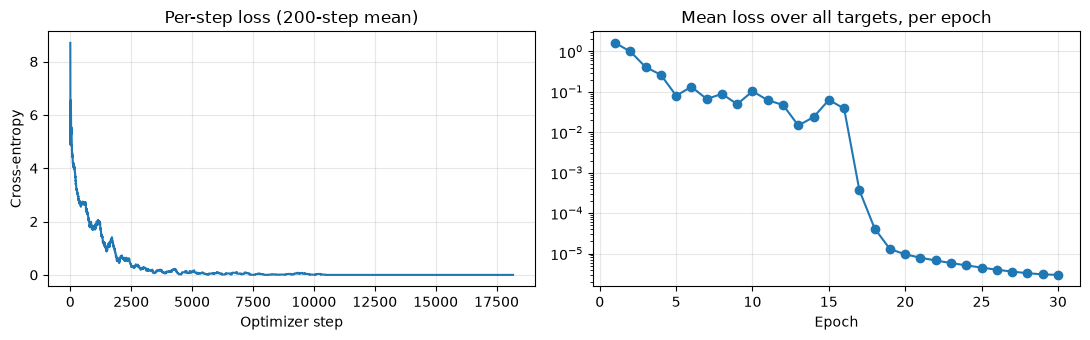

In [63]:
# Class cell 11: verify that parameters changed.
after_state = model_ft.state_dict()
changed_tensors = [k for k in weights_before if not torch.equal(weights_before[k], after_state[k])]
delta = (after_state[tracked] - weights_before[tracked]).abs()
print(f"Tensors changed: {len(changed_tensors)} of {len(weights_before)}")
print(f"{tracked}: mean |change| {delta.mean().item():.4f}, max {delta.max().item():.4f}, "
      f"{int((delta > 0).sum())}/{delta.numel()} values changed")
# The original checkpoint copy is untouched:
assert all(torch.equal(v, base_model.state_dict()[k]) for k, v in slm.state.items())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(pd.Series(step_losses).rolling(200, min_periods=1).mean())
ax[0].set(title="Per-step loss (200-step mean)", xlabel="Optimizer step", ylabel="Cross-entropy")
ax[1].plot(range(1, FINETUNE_EPOCHS + 1), epoch_losses, marker="o")
ax[1].set(title="Mean loss over all targets, per epoch", xlabel="Epoch", yscale="log")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [64]:
after = {q["id"]: ask(model_ft, q["question"]) for q in questions}
compare_rows = []
for q in questions:
    sb = score_answer(before[q["id"]], q["key_facts"], topic_words(q["source"]), known_words)
    sa = score_answer(after[q["id"]], q["key_facts"], topic_words(q["source"]), known_words)
    compare_rows.append({"Question": q["id"], "Before Fine-Tuning": before[q["id"]], "Score before": sb["score"],
                         "After Fine-Tuning": after[q["id"]], "Score after": sa["score"], "Correct after": sa["correct"]})
ft_compare_df = pd.DataFrame(compare_rows)
display(ft_compare_df)

print("Held-out wording (never trained on):")
held_rows = []
for h in HELD_OUT:
    a = ask(model_ft, h["question"])
    s = score_answer(a, h["key_facts"], topic_words(h["source"]), known_words)
    held_rows.append({"Question": h["question"], "Fine-tuned answer": a, "Correct": s["correct"], "Score": s["score"]})
display(pd.DataFrame(held_rows))

print("Original-corpus prompt 'students ' (greedy, 60 chars):")
print("  before:", repr(slm.generate(base_model, "students ", 60, stop_at_newline=False)))
print("  after: ", repr(slm.generate(model_ft, "students ", 60, stop_at_newline=False)))

,Question,Before Fine-Tuning,Score before,After Fine-Tuning,Score after,Correct after
0,Q1,small language models can run on local computers.,2,the lumen pro plan costs nine dollars a month.,10,True
1,Q2,inference uses previously learned parameters.,2,new users get a seven day free trial.,10,True
2,Q3,the university offers courses in informatics.,2,refunds are paid back within five days.,10,True
3,Q4,traches artificial intelligence systems.,2,support is open from nine to five on weekdays.,10,True
4,Q5,tartup applications use models and views.,2,pro members get two mock interviews each week.,10,True


Held-out wording (never trained on):


,Question,Fine-tuned answer,Correct,Score
0,what is the price of pro,the ou ine dollars a month.,False,2
1,how long do refunds take,the day within feven days.,False,2


Original-corpus prompt 'students ' (greedy, 60 chars):
  before: 'experiment with language models.\nartificial intelligence can'
  after:  'with with lan a scha laemail get half off.\ns.\nrs get two moc'


In [65]:
finetune_metrics = {
    "SLM Architecture": f"TinyTransformerLM, experiment {slm.experiment}: " + ", ".join(f"{k}={v}" for k, v in slm.config.items()),
    "Total Parameters": f"{sum(p.numel() for p in model_ft.parameters()):,}",
    "Number of Fine-Tuning Examples": f"{len(training_pairs)} Q/A pairs ({len(train_examples)} character targets)",
    "Learning Rate": f"{FINETUNE_LR} (AdamW, linear decay to 0)",
    "Fine-Tuning Steps": f"{len(step_losses):,} ({FINETUNE_EPOCHS} epochs x {len(train_examples)} targets)",
    "Initial Fine-Tuning Loss": round(initial_loss, 4),
    "Final Fine-Tuning Loss": round(final_loss, 4),
    "Fine-Tuning Time": f"{finetune_seconds:.1f} s (CPU)",
    "Were Weights Updated?": f"Yes: {len(changed_tensors)} of {len(weights_before)} tensors changed",
}
display(Markdown("| Metric | Result |\n|---|---|\n" + "\n".join(f"| {k} | {v} |" for k, v in finetune_metrics.items())))
ft_compare_df.to_csv("finetuning_before_after.csv", index=False)

| Metric | Result |
|---|---|
| SLM Architecture | TinyTransformerLM, experiment 4: embedding_dim=48, num_heads=2, num_layers=2, feedforward_dim=192, context_length=32 |
| Total Parameters | 60,795 |
| Number of Fine-Tuning Examples | 14 Q/A pairs (606 character targets) |
| Learning Rate | 0.001 (AdamW, linear decay to 0) |
| Fine-Tuning Steps | 18,180 (30 epochs x 606 targets) |
| Initial Fine-Tuning Loss | 8.2331 |
| Final Fine-Tuning Loss | 0.0 |
| Fine-Tuning Time | 31.1 s (CPU) |
| Were Weights Updated? | Yes: 30 of 30 tensors changed |

In [66]:
# How much does the outcome depend on the seed (the shuffle order of the 606 targets)?
# Same data, same settings, same starting checkpoint; only the seed changes.
robust_rows = []
for seed in (SEED, 7, 123):
    m = model_ft if seed == SEED else fine_tune(seed)[0]
    trained = sum(score_answer(ask(m, q["question"]), q["key_facts"], topic_words(q["source"]), known_words)["correct"]
                  for q in questions)
    held = sum(score_answer(ask(m, h["question"]), h["key_facts"], topic_words(h["source"]), known_words)["correct"]
               for h in HELD_OUT)
    robust_rows.append({"Seed": seed, "Final loss": round(mean_loss(m, train_examples), 4),
                        "Evaluation questions correct (of 5)": trained, "Held-out wording correct (of 2)": held})
robustness_df = pd.DataFrame(robust_rows)
robustness_df

,Seed,Final loss,Evaluation questions correct (of 5),Held-out wording correct (of 2)
0,42,0.0,5,0
1,7,0.0,5,2
2,123,0.0,5,0


## Step 3.4: Analysis

1. **Did the SLM's responses change after fine-tuning?**
**Yes, all five.** Each answer changed from an unrelated corpus sentence (*"small language models can run on local computers."* for the price question) to the exact Lumen Prep sentence.

2. **Did fine-tuning improve factual accuracy?**
**On the trained questions, yes, and reliably:** 0/5 correct before, **5/5 after**, mean score 2.0 → 10.0. The seed check reproduced 5/5 with three different seeds. **On new wording, no, or only by luck.** The held-out questions scored 0/2, 2/2 and 0/2 across the three seeds. The seed-42 model answered *"what is the price of pro"* with *"the ou ine dollars a month."*: the right fact, with corrupted words. The model mostly memorised the question strings, and transfer to new phrasing is fragile.

3. **Did training loss decrease?**
**Yes**, from 8.2331 to below 0.0001 (displayed as 0.0), the mean over all 606 answer characters. The learning rate decays linearly to zero, so the run ends settled. An earlier version with a constant rate ended mid-oscillation, and its result varied between runs (3/5 vs 5/5). That instability is why the decay and the seed check were added.

4. **Were the model's weights updated?**
**Yes.** All 30 parameter tensors changed, including all 1,296 values of the token embedding. The original checkpoint was kept untouched for the comparison, and an assert checks that.

5. **Can a fine-tuned SLM still generate incorrect or unsupported information?**
**Yes.** Reworded questions got confident, partly invented answers: *"the day within feven days."* for *"how long do refunds take"*. Fine-tuning also caused **catastrophic forgetting**. Given its original prompt `"students "`, the model no longer writes *"experiment with language models."* but *"with with lan a scha laemail get half off..."*, which mixes Lumen Prep facts into its old knowledge.

# Part 4: Comparing Baseline, RAG and Fine-Tuning

## Step 4.1: Compare Three Conditions

All three conditions come from the same checkpoint and use the same five questions and the same greedy decoding:
- **A, Baseline:** `base_model` with prompt `question + "\n"`.
- **B, RAG:** `base_model` with Part 2's best RAG setup: top-1 TF-IDF retrieval, laid out with Configuration B (compact question + keyword snippet), the only layout that puts facts inside the 32-character window.
- **C, Fine-tuned:** `model_ft` with prompt `question + "\n"`, no retrieval.

Each condition is scored on the brief's four criteria:
- **Factual accuracy:** the number of correct answers, and the 0-6 accuracy component of the score.
- **Relevance:** the 0-2 relevance component of the score.
- **Response consistency:** the answer is regenerated with sampling (T=0.5) under 5 seeds. Consistency is the share of those runs that agree with the greedy answer on correctness.
- **Unsupported or invented information:** a confident answer of three or more real words that contains no correct fact. These are flagged per answer.

A fourth column, RAG applied to the fine-tuned model, is included because the final analysis asks whether the two approaches combine.

In [67]:
CONDITIONS = {
    "Baseline SLM": lambda q, **kw: slm.generate(base_model, q + "\n", 50, **kw),
    "SLM + RAG": lambda q, **kw: slm.generate(base_model, build_compact_prompt(q, retrieve(q, 1)), 50, **kw),
    "Fine-Tuned SLM": lambda q, **kw: slm.generate(model_ft, q + "\n", 50, **kw),
    "RAG + Fine-Tuned (extra)": lambda q, **kw: slm.generate(model_ft, build_compact_prompt(q, retrieve(q, 1)), 50, **kw),
}

def invented(answer, s):
    words = [w.strip(".") for w in answer.split() if w.strip(".")]
    return (not s["correct"]) and sum(w in known_words for w in words) >= 3

table, detail = [], []
for q in questions:
    row = {"Question": f"{q['id']}: {q['question']}"}
    for name, fn in CONDITIONS.items():
        answer = fn(q["question"])
        s = score_answer(answer, q["key_facts"], topic_words(q["source"]), known_words)
        samples = [score_answer(fn(q["question"], temperature=0.5, seed=SEED + i), q["key_facts"],
                                topic_words(q["source"]), known_words)["correct"] for i in range(5)]
        row[name] = f"{answer} [{s['score']}/10]"
        detail.append({"Condition": name, "Question": q["id"], "Answer": answer, **s,
                       "consistency": sum(c == s["correct"] for c in samples) / len(samples),
                       "invented": invented(answer, s)})
    table.append(row)
comparison_df = pd.DataFrame(table)
detail_df = pd.DataFrame(detail)
display(Markdown("| " + " | ".join(comparison_df.columns) + " |\n|" + "---|" * len(comparison_df.columns) + "\n" +
                 "\n".join("| " + " | ".join(str(v) for v in r) + " |" for r in comparison_df.values)))

| Question | Baseline SLM | SLM + RAG | Fine-Tuned SLM | RAG + Fine-Tuned (extra) |
|---|---|---|---|---|
| Q1: what does lumen pro cost | small language models can run on local computers. [2/10] | small language models can run on local computers. [2/10] | the lumen pro plan costs nine dollars a month. [10/10] | the pro plan at any time. [3/10] |
| Q2: how long is the free trial | inference uses previously learned parameters. [2/10] | ming [1/10] | new users get a seven day free trial. [10/10] | new users get a seven day free trial. [10/10] |
| Q3: when are refunds paid back | the university offers courses in informatics. [2/10] | the professor teaches artificial intelligence. [2/10] | refunds are paid back within five days. [10/10] | refiars a mont aree deven days. [1/10] |
| Q4: when is support open | traches artificial intelligence systems. [2/10] | training changes the weights of a neural network. [2/10] | support is open from nine to five on weekdays. [10/10] | pro mock interviews each week. [2/10] |
| Q5: how many mock interviews | tartup applications use models and views. [2/10] | tartup applications use models and views. [2/10] | pro members get two mock interviews each week. [10/10] | pro members get two mock interviews each week. [10/10] |

In [68]:
scorecard = detail_df.groupby("Condition", sort=False).agg(
    **{"Correct (of 5)": ("correct", "sum"),
       "Mean score (1-10)": ("score", "mean"),
       "Accuracy (0-6)": ("accuracy", "mean"),
       "Relevance (0-2)": ("relevance", "mean"),
       "Clarity (0-2)": ("clarity", "mean"),
       "Consistency": ("consistency", "mean"),
       "Invented answers": ("invented", "sum")}).round(2)
display(scorecard)
comparison_df.to_csv("three_condition_comparison.csv", index=False)
detail_df.to_csv("three_condition_scores.csv", index=False)

,Correct (of 5),Mean score (1-10),Accuracy (0-6),Relevance (0-2),Clarity (0-2),Consistency,Invented answers
Condition,,,,,,,
Baseline SLM,0,2.0,0.0,0.00,1.83,1.0,5
SLM + RAG,0,1.8,0.0,0.00,1.53,1.0,4
Fine-Tuned SLM,5,10.0,6.0,2.00,2.00,1.0,0
RAG + Fine-Tuned (extra),2,5.2,2.4,0.98,1.73,1.0,2


## Step 4.2: Final Analysis

**Step 4.1 comparison table** (copied from the output above; the score after each answer is out of 10):

| Question | Baseline SLM | SLM + RAG | Fine-Tuned SLM | RAG + Fine-Tuned (extra) |
|---|---|---|---|---|
| Q1: what does lumen pro cost | small language models can run on local computers. [2/10] | small language models can run on local computers. [2/10] | the lumen pro plan costs nine dollars a month. [10/10] | the pro plan at any time. [3/10] |
| Q2: how long is the free trial | inference uses previously learned parameters. [2/10] | ming [1/10] | new users get a seven day free trial. [10/10] | new users get a seven day free trial. [10/10] |
| Q3: when are refunds paid back | the university offers courses in informatics. [2/10] | the professor teaches artificial intelligence. [2/10] | refunds are paid back within five days. [10/10] | refiars a mont aree deven days. [1/10] |
| Q4: when is support open | traches artificial intelligence systems. [2/10] | training changes the weights of a neural network. [2/10] | support is open from nine to five on weekdays. [10/10] | pro mock interviews each week. [2/10] |
| Q5: how many mock interviews | tartup applications use models and views. [2/10] | tartup applications use models and views. [2/10] | pro members get two mock interviews each week. [10/10] | pro members get two mock interviews each week. [10/10] |

**Scorecard**, from the table above:

| Condition | Correct | Mean score | Relevance (0-2) | Consistency | Invented answers |
|---|---|---|---|---|---|
| Baseline SLM | 0/5 | 2.0 | 0.00 | 1.00 | 5 |
| SLM + RAG (layout B, top-1) | 0/5 | 1.8 | 0.00 | 1.00 | 4 |
| **Fine-Tuned SLM** | **5/5** | **10.0** | **2.00** | 1.00 | **0** |
| RAG + Fine-Tuned (extra) | 2/5 | 5.2 | 0.98 | 1.00 | 2 |

How the four criteria were measured:
- **Factual accuracy:** the key fact is present in the answer.
- **Relevance:** the share of the source document's words that appear in the answer.
- **Consistency:** the share of five sampled runs (T=0.5) that match the greedy answer on correctness.
- **Invented:** a fluent answer (three or more real words) with no correct fact.

The baseline is *consistently* wrong and invents an answer every time. It confidently states unrelated sentences from its corpus.

1. **Which condition produced the most accurate responses?**
**Fine-tuning:** 5/5 correct, 10.0/10 mean, and no invented answers on the evaluation questions. It was 5/5 under all three seeds. Baseline and RAG were both 0/5.

2. **Which approach required updating model weights?**
**Fine-tuning only.** It changed 30 of 30 tensors. RAG was verified to leave every weight identical to the checkpoint.

3. **Which approach would be easier to maintain when information changes?**
**RAG.** Changing a policy means editing one document and rebuilding the TF-IDF index, which takes milliseconds. Fine-tuning means retraining (31 s here, far more for a real model) and re-testing every question. Each round also causes more forgetting: this model lost its original sentences after one round. It also only answered reliably in the exact wordings it was trained on.

4. **Which approach would you recommend for a startup with frequently changing policies?**
**RAG, on a pretrained model that can read retrieved text.** The retrieval half worked perfectly here: recall@1 was 5/5. What failed was the 60K-parameter generator, which ignored a fact sitting in its input. Fine-tuning won this experiment only because the questions matched the training wordings. For facts that change monthly and questions users phrase freely, retrieval plus a capable reader is the maintainable design. Fine-tuning fits stable behaviour such as tone and output format.

5. **Could RAG and fine-tuning be combined in the same language model?**
**Yes**, and that is how small models are usually made to use retrieval: fine-tune on *(retrieved passage + question → answer)* examples, then supply fresh passages at inference. Our extra column shows why the training format matters. RAG on a model fine-tuned *without* passages scored 2/5, worse than fine-tuning alone (5/5). The unfamiliar evidence in the prompt pulled it off its memorised answers (Q1 became *"the pro plan at any time."*). A real combination needs the passages in the training examples and a context window much larger than 32 characters.